In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path("/home/bannanakid/RCRL_on_RCMDP")
RUN = 1
CALIBRATION_FILE = PROJECT / "data_train" / "HalfCheetahUnconstrained" / f"run{RUN}" / "metric_calibration" / "baseline_metrics.npz"
VALIDATION_FILE = PROJECT / "data_train" / "HalfCheetahUnconstrained" / f"run{RUN}" / "metric_calibration" / "validation_metrics.npz"
OUTPUT = PROJECT / "plot_data" / "HalfCheetahUnconstrained" / f"run{RUN}" / "metric_analysis"
OUTPUT.mkdir(parents=True, exist_ok=True)

cal = {k: v.copy() for k, v in np.load(CALIBRATION_FILE, allow_pickle=False).items()}
val = {k: v.copy() for k, v in np.load(VALIDATION_FILE, allow_pickle=False).items()}
joint_names = [str(x) for x in cal["joint_names"]]

print("Calibration:", CALIBRATION_FILE)
print("Validation:", VALIDATION_FILE)
print("Calibration episodes:", len(np.unique(cal["episode"])))
print("Validation episodes:", len(np.unique(val["episode"])))
print("Calibration first seed:", int(cal["first_seed"]))
print("Validation first seed:", int(val["first_seed"]))

Calibration: /home/bannanakid/RCRL_on_RCMDP/data_train/HalfCheetahUnconstrained/run1/metric_calibration/baseline_metrics.npz
Validation: /home/bannanakid/RCRL_on_RCMDP/data_train/HalfCheetahUnconstrained/run1/metric_calibration/validation_metrics.npz
Calibration episodes: 100
Validation episodes: 50
Calibration first seed: 5
Validation first seed: 1005


In [3]:
def stats(values):
    values = np.asarray(values, dtype=np.float64)
    return {
        "mean": float(np.mean(values)),
        "median": float(np.median(values)),
        "p90": float(np.percentile(values, 90)),
        "p95": float(np.percentile(values, 95)),
        "p99": float(np.percentile(values, 99)),
        "maximum": float(np.max(values)),
    }

def longest_run(mask):
    mask = np.asarray(mask, dtype=bool)
    best = 0
    current = 0
    for value in mask:
        if value:
            current += 1
            best = max(best, current)
        else:
            current = 0
    return best

def run_count(mask):
    mask = np.asarray(mask, dtype=bool)
    if len(mask) == 0:
        return 0
    return int(mask[0]) + int(np.sum(mask[1:] & ~mask[:-1]))

def episode_violation_metrics(values, episodes, threshold):
    values = np.asarray(values)
    episodes = np.asarray(episodes)
    unique = np.unique(episodes)
    violated = []
    longest = []
    events = []
    for ep in unique:
        mask = values[episodes == ep] > threshold
        violated.append(np.any(mask))
        longest.append(longest_run(mask))
        events.append(run_count(mask))
    return {
        "step_violation_rate": float(np.mean(values > threshold)),
        "episode_violation_frequency": float(np.mean(violated)),
        "longest_violation_run": int(np.max(longest)),
        "mean_violation_events_per_episode": float(np.mean(events)),
    }

def histogram_overlap(a, b, bins=100):
    low = min(float(np.min(a)), float(np.min(b)))
    high = max(float(np.max(a)), float(np.max(b)))
    edges = np.linspace(low, high, bins + 1)
    ha, _ = np.histogram(a, bins=edges, density=True)
    hb, _ = np.histogram(b, bins=edges, density=True)
    return float(np.sum(np.minimum(ha, hb) * np.diff(edges)))

def relative_difference(reference, comparison):
    reference = float(reference)
    comparison = float(comparison)
    return abs(comparison - reference) / max(abs(reference), 1e-12)

In [4]:
pitch_cal = np.asarray(cal["torso_pitch_abs"], dtype=np.float64)
pitch_val = np.asarray(val["torso_pitch_abs"], dtype=np.float64)
joint_cal = np.asarray(cal["joint_speeds"], dtype=np.float64)
joint_val = np.asarray(val["joint_speeds"], dtype=np.float64)

pitch_threshold = float(np.percentile(pitch_cal, 99))
joint_thresholds = np.percentile(joint_cal, 99, axis=0)
pitch_scale = pitch_threshold
joint_scales = joint_thresholds.copy()

pitch_table = pd.DataFrame(
    [
        {"dataset": "calibration", **stats(pitch_cal)},
        {"dataset": "validation", **stats(pitch_val)},
    ]
)

joint_rows = []
for i, name in enumerate(joint_names):
    joint_rows.append({"joint": name, "dataset": "calibration", **stats(joint_cal[:, i])})
    joint_rows.append({"joint": name, "dataset": "validation", **stats(joint_val[:, i])})
joint_table = pd.DataFrame(joint_rows)

display(pitch_table)
display(joint_table)
print("Pitch threshold:", pitch_threshold)
print("Joint-speed thresholds:", joint_thresholds)
print("Pitch scale:", pitch_scale)
print("Joint-speed scales:", joint_scales)

def longest_violation_details(values, episodes, steps, threshold):
    best_length = 0
    best_episode = None
    best_start = None
    best_end = None

    for ep in np.unique(episodes):
        mask = episodes == ep
        ep_values = values[mask]
        ep_steps = steps[mask]
        violations = ep_values > threshold

        current_start = None

        for i, violation in enumerate(violations):
            if violation and current_start is None:
                current_start = i

            if current_start is not None and (not violation or i == len(violations) - 1):
                end = i if violation else i - 1
                length = end - current_start + 1

                if length > best_length:
                    best_length = length
                    best_episode = int(ep)
                    best_start = int(ep_steps[current_start])
                    best_end = int(ep_steps[end])

                current_start = None

    return best_episode, best_start, best_end, best_length


violation_episode, violation_start, violation_end, violation_length = longest_violation_details(
    pitch_cal,
    cal["episode"],
    cal["step"],
    pitch_threshold,
)

episode_mask = cal["episode"] == violation_episode
violation_seed = int(cal["reset_seed"][episode_mask][0])

print("Episode:", violation_episode)
print("Seed:", violation_seed)
print("Violation starts:", violation_start)
print("Violation ends:", violation_end)
print("Length:", violation_length)
print("Threshold:", pitch_threshold)
print("Maximum pitch:", np.max(pitch_cal[episode_mask]))
print("Maximum excess:", np.max(pitch_cal[episode_mask]) - pitch_threshold)


,dataset,mean,median,p90,p95,p99,maximum
0,calibration,1.012063,0.295578,2.913122,3.015053,3.115531,3.141582
1,validation,1.045131,0.319025,2.950976,3.001947,3.112259,3.141501


,joint,dataset,mean,median,p90,p95,p99,maximum
0,back_thigh,calibration,8.595419,7.820627,18.487915,21.080378,23.952443,29.429453
1,back_thigh,validation,8.576333,7.918174,18.249081,20.921308,23.762266,29.536739
2,back_shin,calibration,7.468900,6.906830,14.798329,17.421915,21.273921,31.513311
3,back_shin,validation,7.311740,6.684327,14.566046,17.145523,21.096232,30.192995
4,back_foot,calibration,5.757606,4.156688,14.317458,17.252583,20.869861,37.602210
5,back_foot,validation,5.666121,4.156602,13.814736,16.759751,20.740576,28.697966
6,front_thigh,calibration,10.329150,9.639989,20.841154,23.387763,27.172519,33.250206
7,front_thigh,validation,10.193968,9.472210,20.603873,23.214526,26.954977,32.979598
8,front_shin,calibration,6.228194,5.331445,12.841555,15.437073,21.158679,34.579036
9,front_shin,validation,6.181809,5.288353,12.736117,15.306667,21.117027,33.235771


Pitch threshold: 3.115530983438603
Joint-speed thresholds: [23.9524427  21.27392078 20.86986086 27.17251927 21.15867917 16.23436639]
Pitch scale: 3.115530983438603
Joint-speed scales: [23.9524427  21.27392078 20.86986086 27.17251927 21.15867917 16.23436639]
Episode: 77
Seed: 81
Violation starts: 799
Violation ends: 802
Length: 4
Threshold: 3.115530983438603
Maximum pitch: 3.1408182055101928
Maximum excess: 0.02528722207158962


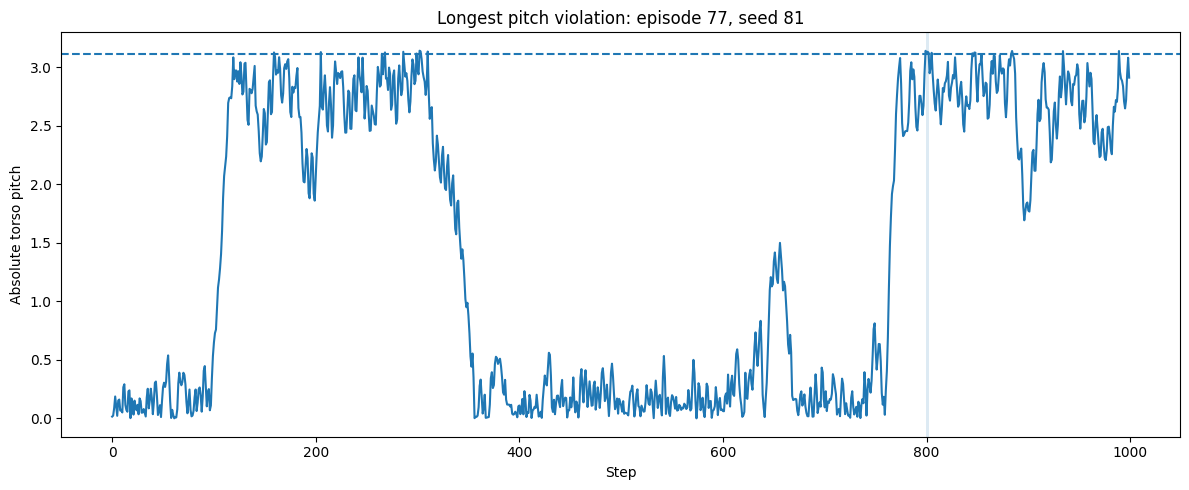

In [5]:
mask = cal["episode"] == violation_episode

plt.figure(figsize=(12, 5))
plt.plot(cal["step"][mask], pitch_cal[mask])
plt.axhline(pitch_threshold, linestyle="--")
plt.axvspan(violation_start, violation_end, alpha=0.15)
plt.xlabel("Step")
plt.ylabel("Absolute torso pitch")
plt.title(
    f"Longest pitch violation: episode {violation_episode}, seed {violation_seed}"
)
plt.tight_layout()
plt.show()

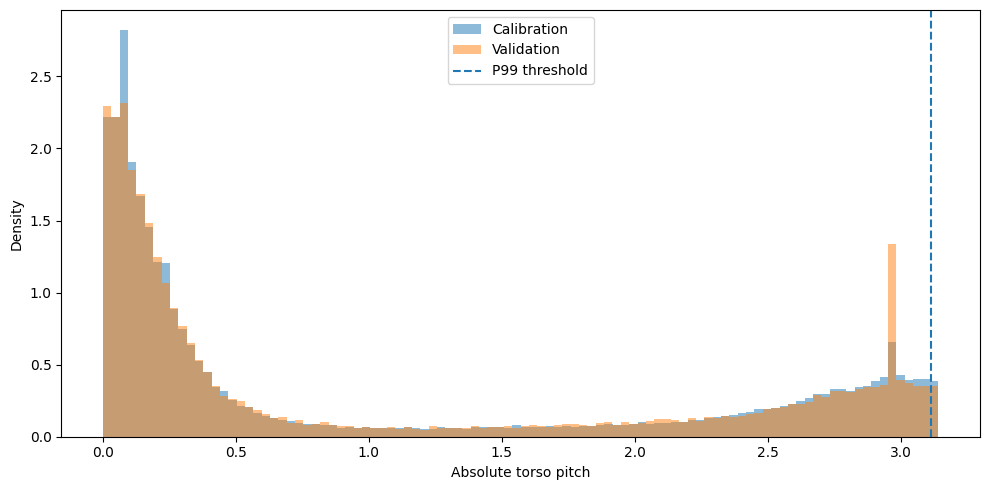

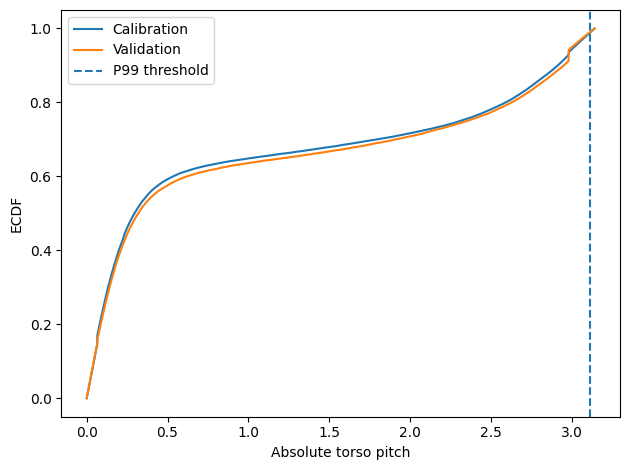

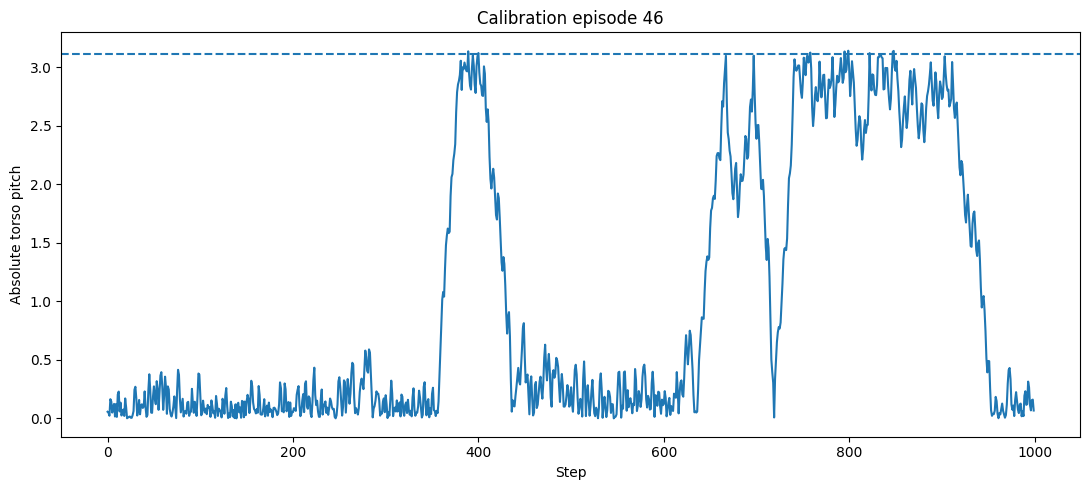

In [6]:
plt.figure(figsize=(10, 5))
plt.hist(pitch_cal, bins=100, density=True, alpha=0.5, label="Calibration")
plt.hist(pitch_val, bins=100, density=True, alpha=0.5, label="Validation")
plt.axvline(pitch_threshold, linestyle="--", label="P99 threshold")
plt.xlabel("Absolute torso pitch")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

for values, label in [(pitch_cal, "Calibration"), (pitch_val, "Validation")]:
    x = np.sort(values)
    y = np.arange(1, len(x) + 1) / len(x)
    plt.plot(x, y, label=label)
plt.axvline(pitch_threshold, linestyle="--", label="P99 threshold")
plt.xlabel("Absolute torso pitch")
plt.ylabel("ECDF")
plt.legend()
plt.tight_layout()
plt.show()

cal_pitch_episode_max = pd.Series(pitch_cal).groupby(cal["episode"]).max()
worst_pitch_episode = int(cal_pitch_episode_max.idxmax())
mask = cal["episode"] == worst_pitch_episode

plt.figure(figsize=(11, 5))
plt.plot(cal["step"][mask], pitch_cal[mask])
plt.axhline(pitch_threshold, linestyle="--")
plt.xlabel("Step")
plt.ylabel("Absolute torso pitch")
plt.title(f"Calibration episode {worst_pitch_episode}")
plt.tight_layout()
plt.show()

In [7]:
pitch_cal_metrics = episode_violation_metrics(pitch_cal, cal["episode"], pitch_threshold)
pitch_val_metrics = episode_violation_metrics(pitch_val, val["episode"], pitch_threshold)

pitch_comparison = pd.DataFrame(
    [
        {
            "metric": "histogram_overlap",
            "calibration": 1.0,
            "validation": histogram_overlap(pitch_cal, pitch_val),
        },
        {
            "metric": "p95_relative_difference",
            "calibration": 0.0,
            "validation": relative_difference(np.percentile(pitch_cal, 95), np.percentile(pitch_val, 95)),
        },
        {
            "metric": "p99_relative_difference",
            "calibration": 0.0,
            "validation": relative_difference(np.percentile(pitch_cal, 99), np.percentile(pitch_val, 99)),
        },
        {
            "metric": "step_violation_rate",
            "calibration": pitch_cal_metrics["step_violation_rate"],
            "validation": pitch_val_metrics["step_violation_rate"],
        },
        {
            "metric": "episode_violation_frequency",
            "calibration": pitch_cal_metrics["episode_violation_frequency"],
            "validation": pitch_val_metrics["episode_violation_frequency"],
        },
        {
            "metric": "longest_violation_run",
            "calibration": pitch_cal_metrics["longest_violation_run"],
            "validation": pitch_val_metrics["longest_violation_run"],
        },
        {
            "metric": "mean_violation_events_per_episode",
            "calibration": pitch_cal_metrics["mean_violation_events_per_episode"],
            "validation": pitch_val_metrics["mean_violation_events_per_episode"],
        },
    ]
)

display(pitch_comparison)

,metric,calibration,validation
0,histogram_overlap,1.00,0.957840
1,p95_relative_difference,0.00,0.004347
2,p99_relative_difference,0.00,0.001050
3,step_violation_rate,0.01,0.008900
4,episode_violation_frequency,0.86,0.860000
5,longest_violation_run,4.00,3.000000
6,mean_violation_events_per_episode,9.08,8.080000


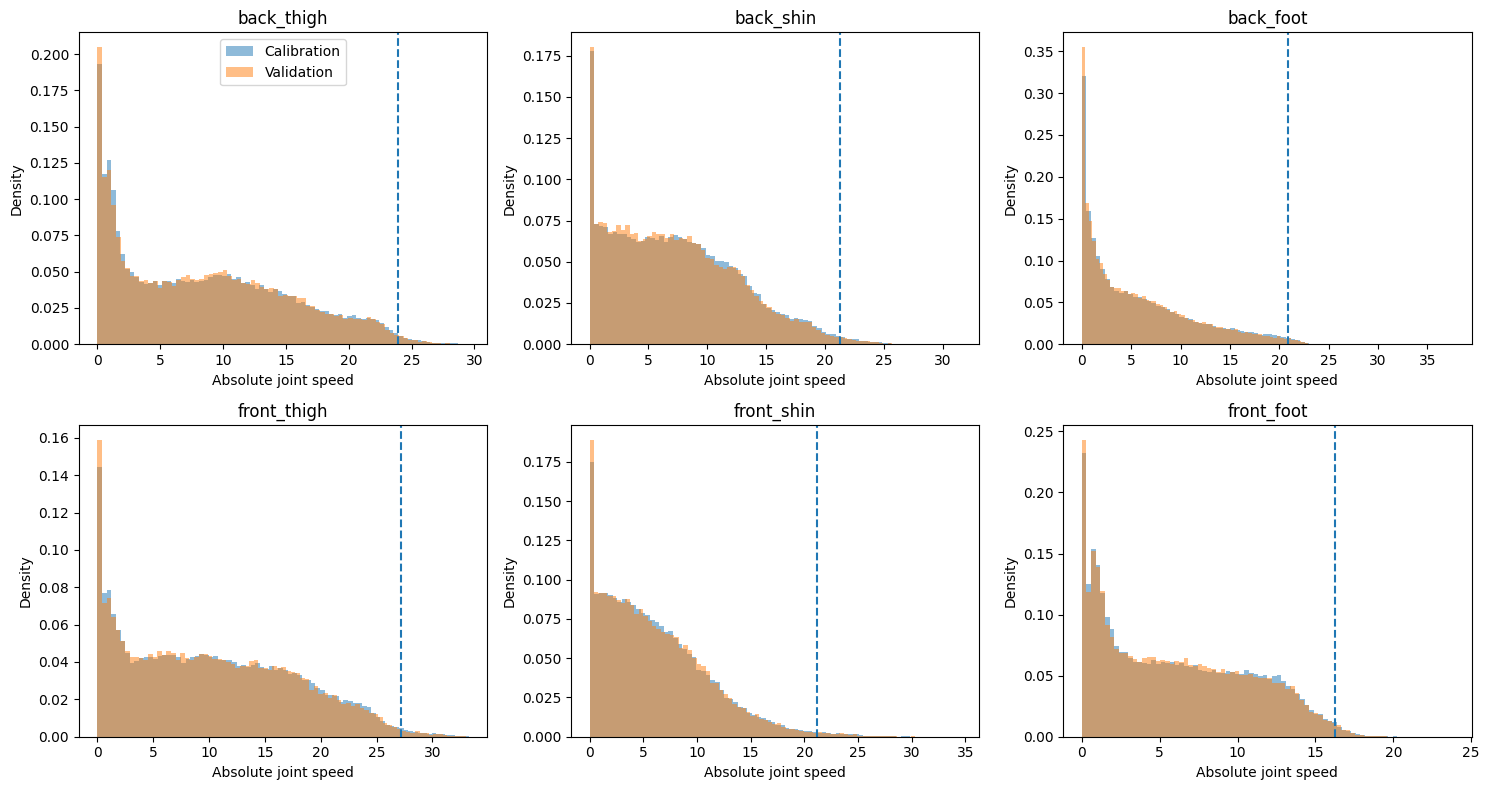

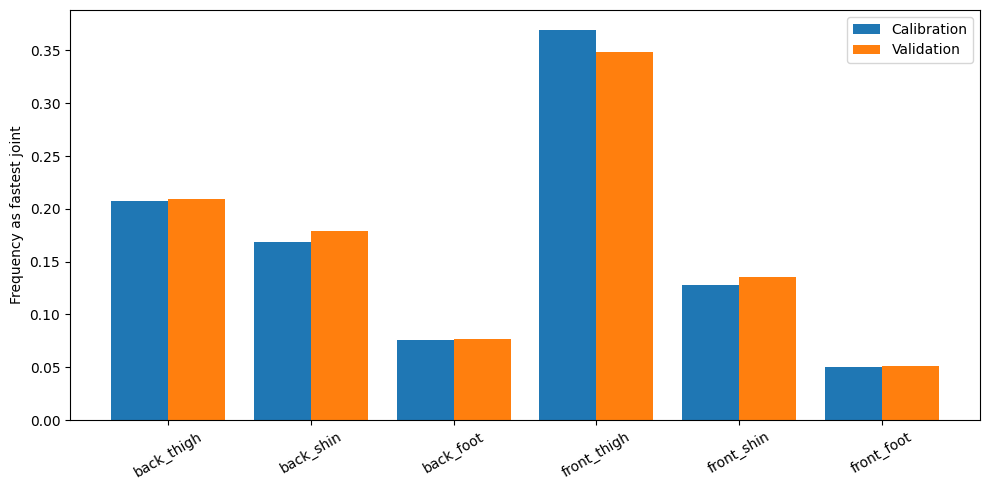

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, name in enumerate(joint_names):
    ax = axes.flat[i]
    ax.hist(joint_cal[:, i], bins=80, density=True, alpha=0.5, label="Calibration")
    ax.hist(joint_val[:, i], bins=80, density=True, alpha=0.5, label="Validation")
    ax.axvline(joint_thresholds[i], linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Absolute joint speed")
    ax.set_ylabel("Density")
axes.flat[0].legend()
plt.tight_layout()
plt.show()

fast_cal = np.bincount(cal["fastest_joint_index"].astype(int), minlength=6) / len(cal["fastest_joint_index"])
fast_val = np.bincount(val["fastest_joint_index"].astype(int), minlength=6) / len(val["fastest_joint_index"])
x = np.arange(6)
width = 0.4

plt.figure(figsize=(10, 5))
plt.bar(x - width / 2, fast_cal, width, label="Calibration")
plt.bar(x + width / 2, fast_val, width, label="Validation")
plt.xticks(x, joint_names, rotation=30)
plt.ylabel("Frequency as fastest joint")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
joint_comparison_rows = []

for i, name in enumerate(joint_names):
    cal_metrics = episode_violation_metrics(joint_cal[:, i], cal["episode"], joint_thresholds[i])
    val_metrics = episode_violation_metrics(joint_val[:, i], val["episode"], joint_thresholds[i])
    joint_comparison_rows.append(
        {
            "joint": name,
            "histogram_overlap": histogram_overlap(joint_cal[:, i], joint_val[:, i]),
            "p95_relative_difference": relative_difference(
                np.percentile(joint_cal[:, i], 95),
                np.percentile(joint_val[:, i], 95),
            ),
            "p99_relative_difference": relative_difference(
                np.percentile(joint_cal[:, i], 99),
                np.percentile(joint_val[:, i], 99),
            ),
            "cal_step_violation_rate": cal_metrics["step_violation_rate"],
            "val_step_violation_rate": val_metrics["step_violation_rate"],
            "step_violation_difference": abs(
                val_metrics["step_violation_rate"] - cal_metrics["step_violation_rate"]
            ),
            "cal_episode_violation_frequency": cal_metrics["episode_violation_frequency"],
            "val_episode_violation_frequency": val_metrics["episode_violation_frequency"],
            "episode_violation_difference": abs(
                val_metrics["episode_violation_frequency"]
                - cal_metrics["episode_violation_frequency"]
            ),
            "cal_longest_run": cal_metrics["longest_violation_run"],
            "val_longest_run": val_metrics["longest_violation_run"],
            "cal_events_per_episode": cal_metrics["mean_violation_events_per_episode"],
            "val_events_per_episode": val_metrics["mean_violation_events_per_episode"],
        }
    )

joint_comparison = pd.DataFrame(joint_comparison_rows)
display(joint_comparison)

,joint,histogram_overlap,p95_relative_difference,p99_relative_difference,cal_step_violation_rate,val_step_violation_rate,step_violation_difference,cal_episode_violation_frequency,val_episode_violation_frequency,episode_violation_difference,cal_longest_run,val_longest_run,cal_events_per_episode,val_events_per_episode
0,back_thigh,0.97596,0.007546,0.007940,0.01,0.00896,0.00104,0.98,0.98,0.00,1,1,10.00,8.96
1,back_shin,0.97970,0.015865,0.008352,0.01,0.00932,0.00068,1.00,1.00,0.00,2,1,9.94,9.32
2,back_foot,0.98231,0.028566,0.006195,0.01,0.00890,0.00110,0.94,0.92,0.02,1,1,10.00,8.90
3,front_thigh,0.97634,0.007407,0.008006,0.01,0.00918,0.00082,0.88,0.86,0.02,1,1,10.00,9.18
4,front_shin,0.98069,0.008448,0.001969,0.01,0.00986,0.00014,0.69,0.68,0.01,3,2,9.09,9.08
5,front_foot,0.97558,0.003655,0.003380,0.01,0.01064,0.00064,0.95,0.94,0.01,1,1,10.00,10.64


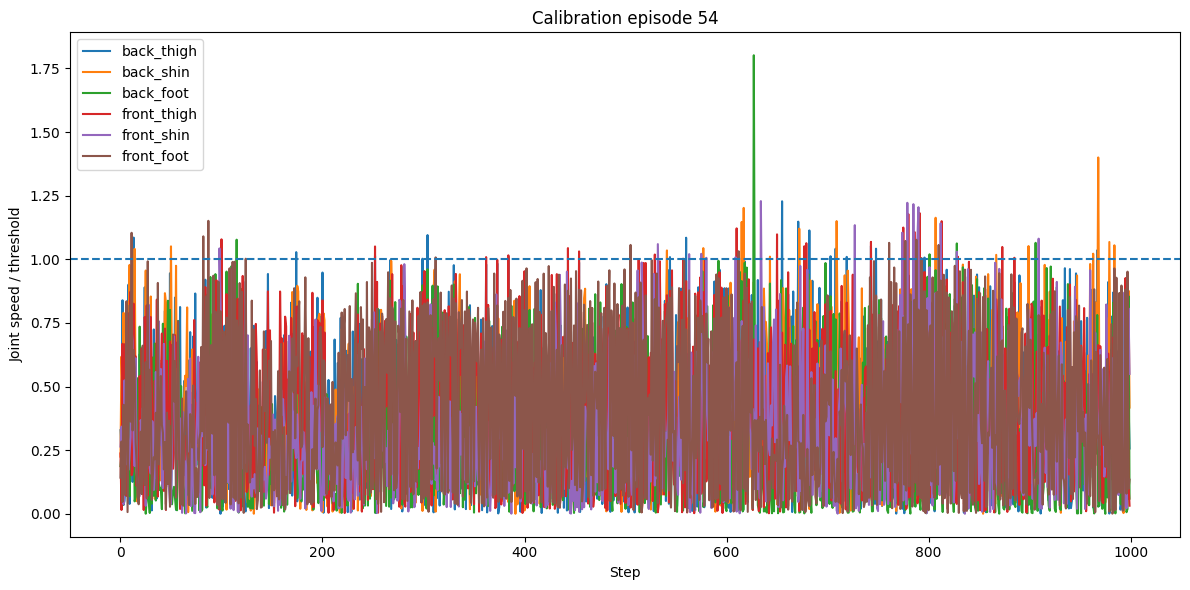

In [10]:
normalized_cal = joint_cal / joint_thresholds
episode_peak = pd.Series(np.max(normalized_cal, axis=1)).groupby(cal["episode"]).max()
worst_joint_episode = int(episode_peak.idxmax())
mask = cal["episode"] == worst_joint_episode

plt.figure(figsize=(12, 6))
for i, name in enumerate(joint_names):
    plt.plot(cal["step"][mask], normalized_cal[mask, i], label=name)
plt.axhline(1.0, linestyle="--")
plt.xlabel("Step")
plt.ylabel("Joint speed / threshold")
plt.title(f"Calibration episode {worst_joint_episode}")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
pitch_overlap = histogram_overlap(pitch_cal, pitch_val)
pitch_p95_diff = relative_difference(np.percentile(pitch_cal, 95), np.percentile(pitch_val, 95))
pitch_p99_diff = relative_difference(np.percentile(pitch_cal, 99), np.percentile(pitch_val, 99))
pitch_step_diff = abs(
    pitch_val_metrics["step_violation_rate"] - pitch_cal_metrics["step_violation_rate"]
)
pitch_episode_diff = abs(
    pitch_val_metrics["episode_violation_frequency"]
    - pitch_cal_metrics["episode_violation_frequency"]
)

pitch_pass = (
    pitch_overlap >= 0.80
    and pitch_p95_diff <= 0.10
    and pitch_p99_diff <= 0.10
    and pitch_step_diff <= 0.02
    and pitch_episode_diff <= 0.10
)

joint_passes = (
    (joint_comparison["histogram_overlap"] >= 0.80)
    & (joint_comparison["p95_relative_difference"] <= 0.10)
    & (joint_comparison["p99_relative_difference"] <= 0.10)
    & (joint_comparison["step_violation_difference"] <= 0.02)
    & (joint_comparison["episode_violation_difference"] <= 0.10)
)

stability = pd.DataFrame(
    [
        {"category": "Pitch", "result": "PASS" if pitch_pass else "REVIEW"},
        {
            "category": "Joint speeds",
            "result": "PASS" if bool(joint_passes.all()) else "REVIEW",
        },
        {
            "category": "Overall",
            "result": "PASS" if pitch_pass and bool(joint_passes.all()) else "REVIEW",
        },
    ]
)

pitch_table.to_csv(OUTPUT / "pitch_statistics.csv", index=False)
joint_table.to_csv(OUTPUT / "joint_statistics.csv", index=False)
pitch_comparison.to_csv(OUTPUT / "pitch_validation.csv", index=False)
joint_comparison.to_csv(OUTPUT / "joint_validation.csv", index=False)
stability.to_csv(OUTPUT / "stability.csv", index=False)

display(stability)
print("Pitch threshold:", pitch_threshold)
print("Joint-speed thresholds:", joint_thresholds)

,category,result
0,Pitch,PASS
1,Joint speeds,PASS
2,Overall,PASS


Pitch threshold: 3.115530983438603
Joint-speed thresholds: [23.9524427  21.27392078 20.86986086 27.17251927 21.15867917 16.23436639]


In [12]:
WRITE_CONFIG = False
MANUAL_PITCH_REVIEW_APPROVED = True
COST_VERSION = "behavior_inversion_15step_v2"

config_text = (
    f"PITCH_THRESHOLD = {pitch_threshold!r}\n"
    f"PITCH_SCALE = {pitch_scale!r}\n"
    f"JOINT_SPEED_THRESHOLDS = {joint_thresholds.tolist()!r}\n"
    f"JOINT_SPEED_SCALES = {joint_scales.tolist()!r}\n"
    f"COST_VERSION = {COST_VERSION!r}\n"
)

print(config_text)

if WRITE_CONFIG:
    overall_pass = (
        stability.loc[
            stability["category"] == "Overall",
            "result"
        ].iloc[0] == "PASS"
    )

    if not overall_pass and not MANUAL_PITCH_REVIEW_APPROVED:
        raise RuntimeError(
            "Overall stability is not PASS and manual review was not approved"
        )

    path = PROJECT / "configs" / "halfcheetah_safety_thresholds.py"
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(config_text)

    print("Written:", path)

PITCH_THRESHOLD = 3.115530983438603
PITCH_SCALE = 3.115530983438603
JOINT_SPEED_THRESHOLDS = [23.952442696579617, 21.273920780514413, 20.869860859139493, 27.172519265909983, 21.158679170546527, 16.234366386891228]
JOINT_SPEED_SCALES = [23.952442696579617, 21.273920780514413, 20.869860859139493, 27.172519265909983, 21.158679170546527, 16.234366386891228]
COST_VERSION = 'behavior_inversion_15step_v2'



In [13]:

import sys
import time
import numpy as np
import torch
import mujoco_py
from mujoco_py.generated import const

sys.path.insert(
    0,
    "/home/bannanakid/RCRL_on_RCMDP",
)

from collect_unconstrained_metrics import (
    ActorGaussian,
    unwrap_reset,
    resolve_actor,
)

from envs.half_cheetah_unconstrained import (
    HalfCheetahUnconstrained,
)

VISUAL_THRESHOLD = 1.45

print(
    "Visual validation threshold:",
    VISUAL_THRESHOLD,
    "rad",
)

print(
    "Visual validation threshold:",
    np.degrees(VISUAL_THRESHOLD),
    "deg",
)

env = HalfCheetahUnconstrained()

actor_path = resolve_actor(
    "/home/bannanakid/RCRL_on_RCMDP/"
    "models/HalfCheetahUnconstrained/"
    "run1/Best_Unconstrained"
)

state = torch.load(
    actor_path,
    map_location="cpu",
)

if "state_dict" in state:
    state = state["state_dict"]

if "actor_state_dict" in state:
    state = state["actor_state_dict"]

actor = ActorGaussian(
    int(state["fc1.weight"].shape[1]),
    int(state["fc1.weight"].shape[0]),
    int(state["mean_layer.weight"].shape[0]),
    float(env.action_space.high[0]),
)

actor.load_state_dict(state)
actor.eval()


def wrapped_abs_pitch(env):
    raw = float(
        env.sim.data.qpos[2]
    )

    wrapped = float(
        np.arctan2(
            np.sin(raw),
            np.cos(raw),
        )
    )

    return (
        raw,
        wrapped,
        abs(wrapped),
    )


obs = unwrap_reset(
    env.reset(
        seed=violation_seed
    )
)

crossing_step = None
step = 0
done = False

while not done:

    x = torch.as_tensor(
        obs,
        dtype=torch.float32,
    ).unsqueeze(0)

    with torch.no_grad():
        action = (
            actor(x)
            .cpu()
            .numpy()
            .reshape(-1)
        )

    action = np.clip(
        action,
        env.action_space.low,
        env.action_space.high,
    )

    (
        obs,
        reward,
        cost,
        truncated,
        terminated,
        info,
    ) = env.step(action)

    (
        pitch_raw,
        pitch_wrapped,
        pitch_abs,
    ) = wrapped_abs_pitch(env)

    if pitch_abs > VISUAL_THRESHOLD:
        crossing_step = step
        break

    done = bool(
        truncated
        or terminated
    )

    step += 1


if crossing_step is None:
    raise RuntimeError(
        f"Seed {violation_seed} never crosses "
        f"{VISUAL_THRESHOLD:.3f} rad"
    )


show_start = max(
    0,
    crossing_step - 40,
)

show_end = min(
    env.max_steps - 1,
    crossing_step + 40,
)

print(
    "Seed:",
    violation_seed,
)

print(
    "First threshold crossing:",
    crossing_step,
)

print(
    "Showing steps:",
    show_start,
    "through",
    show_end,
)


obs = unwrap_reset(
    env.reset(
        seed=violation_seed
    )
)

step = 0
done = False
viewer = None

while (
    not done
    and step <= show_end
):

    x = torch.as_tensor(
        obs,
        dtype=torch.float32,
    ).unsqueeze(0)

    with torch.no_grad():
        action = (
            actor(x)
            .cpu()
            .numpy()
            .reshape(-1)
        )

    action = np.clip(
        action,
        env.action_space.low,
        env.action_space.high,
    )

    (
        obs,
        reward,
        cost,
        truncated,
        terminated,
        info,
    ) = env.step(action)

    (
        pitch_raw,
        pitch_wrapped,
        pitch_abs,
    ) = wrapped_abs_pitch(env)

    excess = max(
        pitch_abs
        - VISUAL_THRESHOLD,
        0.0,
    )

    if step == show_start:
        viewer = mujoco_py.MjViewer(
            env.sim
        )

    if step >= show_start:

        status = (
            "VIOLATION"
            if pitch_abs > VISUAL_THRESHOLD
            else "NORMAL"
        )

        viewer.add_overlay(
            const.GRID_TOPLEFT,
            "RL step",
            str(step),
        )

        viewer.add_overlay(
            const.GRID_TOPLEFT,
            "Raw pitch",
            f"{pitch_raw:.5f}",
        )

        viewer.add_overlay(
            const.GRID_TOPLEFT,
            "Wrapped pitch",
            f"{pitch_wrapped:.5f}",
        )

        viewer.add_overlay(
            const.GRID_TOPLEFT,
            "Abs wrapped pitch",
            f"{pitch_abs:.5f}",
        )

        viewer.add_overlay(
            const.GRID_TOPLEFT,
            "Threshold",
            f"{VISUAL_THRESHOLD:.5f}",
        )

        viewer.add_overlay(
            const.GRID_TOPLEFT,
            "Threshold deg",
            f"{np.degrees(VISUAL_THRESHOLD):.2f}",
        )

        viewer.add_overlay(
            const.GRID_TOPLEFT,
            "Excess",
            f"{excess:.5f}",
        )

        viewer.add_overlay(
            const.GRID_TOPLEFT,
            "State",
            status,
        )

        if step == crossing_step:
            viewer.add_overlay(
                const.GRID_TOPRIGHT,
                "EVENT",
                "FIRST THRESHOLD CROSSING",
            )

        print(
            f"step={step:4d} "
            f"raw={pitch_raw:8.4f} "
            f"wrapped={pitch_wrapped:8.4f} "
            f"abs_wrapped={pitch_abs:7.4f} "
            f"threshold={VISUAL_THRESHOLD:7.4f} "
            f"excess={excess:7.4f} "
            f"{status}",
            flush=True,
        )

        viewer.render()

        time.sleep(
            0.03
        )

    done = bool(
        truncated
        or terminated
    )

    step += 1

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Visual validation threshold: 1.45 rad
Visual validation threshold: 83.07888029396936 deg
Seed: 81
First threshold crossing: 108
Showing steps: 68 through 148


/home/bannanakid/miniforge3/envs/rcrl/lib/python3.10/site-packages/gym/envs/mujoco/mujoco_env.py:190: UserWarning: WARN: This version of the mujoco environments depends on the mujoco-py bindings, which are no longer maintained and may stop working. Please upgrade to the v4 versions of the environments (which depend on the mujoco python bindings instead), unless you are trying to precisely replicate previous works).
  logger.warn(


Creating window glfw
step=  68 raw=  0.2828 wrapped=  0.2828 abs_wrapped= 0.2828 threshold= 1.4500 excess= 0.0000 NORMAL
step=  69 raw=  0.3116 wrapped=  0.3116 abs_wrapped= 0.3116 threshold= 1.4500 excess= 0.0000 NORMAL
step=  70 raw=  0.3897 wrapped=  0.3897 abs_wrapped= 0.3897 threshold= 1.4500 excess= 0.0000 NORMAL
step=  71 raw=  0.3714 wrapped=  0.3714 abs_wrapped= 0.3714 threshold= 1.4500 excess= 0.0000 NORMAL
step=  72 raw=  0.2911 wrapped=  0.2911 abs_wrapped= 0.2911 threshold= 1.4500 excess= 0.0000 NORMAL
step=  73 raw=  0.1376 wrapped=  0.1376 abs_wrapped= 0.1376 threshold= 1.4500 excess= 0.0000 NORMAL
step=  74 raw=  0.0435 wrapped=  0.0435 abs_wrapped= 0.0435 threshold= 1.4500 excess= 0.0000 NORMAL
step=  75 raw=  0.1438 wrapped=  0.1438 abs_wrapped= 0.1438 threshold= 1.4500 excess= 0.0000 NORMAL
step=  76 raw=  0.2464 wrapped=  0.2464 abs_wrapped= 0.2464 threshold= 1.4500 excess= 0.0000 NORMAL
step=  77 raw=  0.0738 wrapped=  0.0738 abs_wrapped= 0.0738 threshold= 1.4500 e

Calibration inversion episodes: 89 / 100
Validation inversion episodes: 45 / 50
Calibration non-inversion episodes: 11
Validation non-inversion episodes: 5



,threshold_rad,threshold_deg,cal_detection_rate,val_detection_rate,cal_median_lead_steps,val_median_lead_steps,cal_median_lead_seconds,val_median_lead_seconds,cal_normal_step_false_positive_rate,val_normal_step_false_positive_rate,cal_nonflip_episode_false_alarm_rate,val_nonflip_episode_false_alarm_rate
51,2.80,160.428183,1.0,1.0,1.0,2.0,0.05,0.10,0.000164,0.000000,0.0,0.0
50,2.75,157.563394,1.0,1.0,2.0,2.0,0.10,0.10,0.000196,0.000000,0.0,0.0
49,2.70,154.698605,1.0,1.0,3.0,3.0,0.15,0.15,0.000229,0.000000,0.0,0.0
48,2.65,151.833816,1.0,1.0,3.0,4.0,0.15,0.20,0.000262,0.000000,0.0,0.0
47,2.60,148.969027,1.0,1.0,4.0,4.0,0.20,0.20,0.000327,0.000000,0.0,0.0
46,2.55,146.104238,1.0,1.0,4.0,4.0,0.20,0.20,0.000393,0.000000,0.0,0.0
45,2.50,143.239449,1.0,1.0,5.0,5.0,0.25,0.25,0.000426,0.000000,0.0,0.0
44,2.45,140.374660,1.0,1.0,5.0,5.0,0.25,0.25,0.000491,0.000000,0.0,0.0
43,2.40,137.509871,1.0,1.0,5.0,5.0,0.25,0.25,0.000524,0.000000,0.0,0.0
42,2.35,134.645082,1.0,1.0,6.0,6.0,0.30,0.30,0.000589,0.000000,0.0,0.0



Recommendation method:
Minimum worst-case normal-step false-positive rate among thresholds with at least 90% inversion detection and at least 5-step median warning lead in both calibration and validation

Recommended pitch threshold: 1.4499999999999997 rad
Recommended pitch threshold: 83.07888029396935 deg
Recommended pitch scale: 1.4499999999999997

Calibration detection rate: 1.0
Validation detection rate: 1.0
Calibration median warning lead: 15.0 steps
Validation median warning lead: 15.0 steps
Calibration normal-step false-positive rate: 0.00788896526891224
Validation normal-step false-positive rate: 0.0035379676341479394


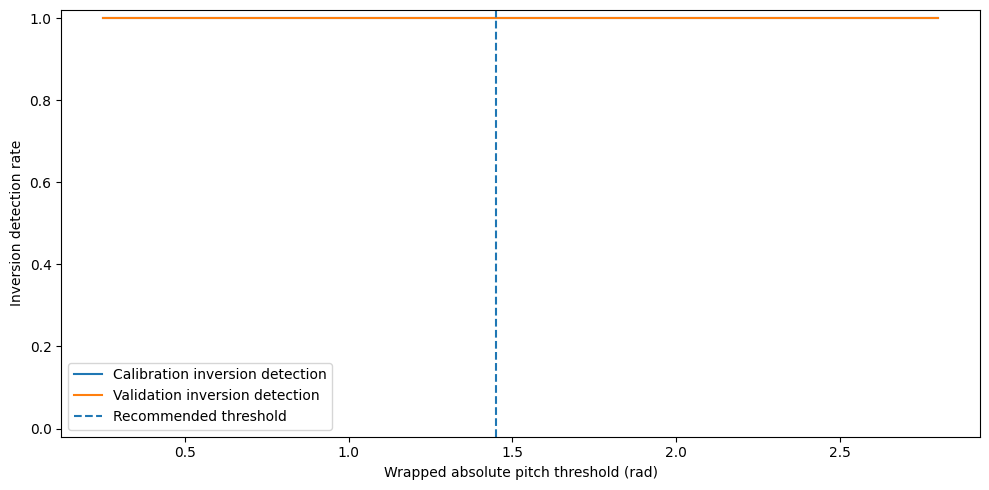

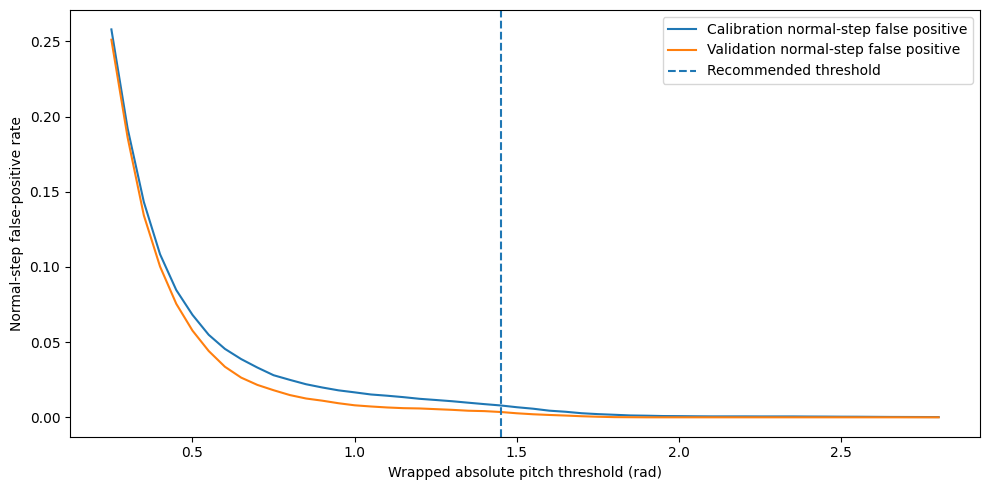

,dataset,episode,event_step,first_threshold_crossing_step,warning_lead_steps,warning_lead_seconds,event_wrapped_abs_pitch
0,calibration,1,154,136,18,0.90,2.906905
1,calibration,2,90,76,14,0.70,3.093406
2,calibration,3,178,163,15,0.75,2.871877
3,calibration,4,584,574,10,0.50,3.046873
4,calibration,5,81,69,12,0.60,2.889217
5,calibration,6,236,216,20,1.00,2.930404
6,calibration,8,218,207,11,0.55,3.081700
7,calibration,9,354,342,12,0.60,3.048259
8,calibration,10,214,199,15,0.75,2.828666
9,calibration,11,136,125,11,0.55,3.092490



Saved: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahUnconstrained/run1/metric_analysis/pitch_behavior_threshold_sweep.csv
Saved: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahUnconstrained/run1/metric_analysis/pitch_flip_event_detection.csv


In [14]:
if "torso_pitch_raw" not in cal or "torso_pitch_raw" not in val:
    raise RuntimeError(
        "Recollect calibration and validation metrics with the wrapped-pitch collector before running this cell"
    )

PRE_EVENT_STEPS = 40
MIN_DETECTION_RATE = 0.90
MIN_MEDIAN_LEAD_STEPS = 15
CONTROL_DT = 0.05
CANDIDATE_THRESHOLDS = np.arange(0.25, 2.81, 0.05)


def inversion_events_and_normal_mask(data):
    episodes = np.asarray(data["episode"], dtype=np.int64)
    steps = np.asarray(data["step"], dtype=np.int64)
    raw = np.asarray(data["torso_pitch_raw"], dtype=np.float64)
    wrapped_abs = np.asarray(data["torso_pitch_abs"], dtype=np.float64)

    normal_mask = np.zeros(len(episodes), dtype=bool)
    events = []
    non_inversion_episodes = []

    for ep in np.unique(episodes):
        idx = np.flatnonzero(episodes == ep)

        ep_raw = raw[idx]
        ep_steps = steps[idx]

        baseline = float(ep_raw[0])
        excursion = np.abs(ep_raw - baseline)

        inversion_local = np.flatnonzero(excursion >= np.pi)

        if len(inversion_local) == 0:
            normal_mask[idx] = True
            non_inversion_episodes.append(int(ep))
            continue

        event_local = int(inversion_local[0])
        event_global = int(idx[event_local])

        hazard_start_local = max(
            0,
            event_local - PRE_EVENT_STEPS,
        )

        if hazard_start_local > 0:
            normal_mask[idx[:hazard_start_local]] = True

        events.append(
            {
                "episode": int(ep),
                "event_global": event_global,
                "event_local": event_local,
                "hazard_start_global": int(
                    idx[hazard_start_local]
                ),
                "event_step": int(
                    ep_steps[event_local]
                ),
                "baseline_raw_pitch": baseline,
                "event_raw_pitch": float(
                    ep_raw[event_local]
                ),
                "event_wrapped_abs_pitch": float(
                    wrapped_abs[event_global]
                ),
            }
        )

    return (
        events,
        normal_mask,
        non_inversion_episodes,
    )


def threshold_metrics(data, threshold):
    episodes = np.asarray(
        data["episode"],
        dtype=np.int64,
    )

    wrapped_abs = np.asarray(
        data["torso_pitch_abs"],
        dtype=np.float64,
    )

    steps = np.asarray(
        data["step"],
        dtype=np.int64,
    )

    (
        events,
        normal_mask,
        non_inversion_episodes,
    ) = inversion_events_and_normal_mask(data)

    detections = []
    lead_steps = []

    for event in events:
        ep = event["episode"]
        event_step = event["event_step"]

        start_step = max(
            0,
            event_step - PRE_EVENT_STEPS,
        )

        mask = (
            (episodes == ep)
            & (steps >= start_step)
            & (steps <= event_step)
        )

        crossing_steps = steps[mask][
            wrapped_abs[mask] > threshold
        ]

        detected = len(crossing_steps) > 0

        detections.append(detected)

        if detected:
            lead_steps.append(
                int(
                    event_step
                    - crossing_steps[0]
                )
            )

    if np.any(normal_mask):
        normal_step_false_positive_rate = float(
            np.mean(
                wrapped_abs[normal_mask]
                > threshold
            )
        )
    else:
        normal_step_false_positive_rate = np.nan

    nonflip_false_alarm = []

    for ep in non_inversion_episodes:
        mask = episodes == ep

        nonflip_false_alarm.append(
            bool(
                np.any(
                    wrapped_abs[mask]
                    > threshold
                )
            )
        )

    return {
        "inversion_episodes": len(events),
        "detection_rate": (
            float(np.mean(detections))
            if detections
            else np.nan
        ),
        "median_lead_steps": (
            float(np.median(lead_steps))
            if lead_steps
            else np.nan
        ),
        "mean_lead_steps": (
            float(np.mean(lead_steps))
            if lead_steps
            else np.nan
        ),
        "median_lead_seconds": (
            float(
                np.median(lead_steps)
                * CONTROL_DT
            )
            if lead_steps
            else np.nan
        ),
        "normal_step_false_positive_rate":
            normal_step_false_positive_rate,
        "nonflip_episode_false_alarm_rate": (
            float(
                np.mean(
                    nonflip_false_alarm
                )
            )
            if nonflip_false_alarm
            else np.nan
        ),
    }


(
    cal_events,
    cal_normal_mask,
    cal_nonflip,
) = inversion_events_and_normal_mask(cal)

(
    val_events,
    val_normal_mask,
    val_nonflip,
) = inversion_events_and_normal_mask(val)

print(
    "Calibration inversion episodes:",
    len(cal_events),
    "/",
    len(np.unique(cal["episode"])),
)

print(
    "Validation inversion episodes:",
    len(val_events),
    "/",
    len(np.unique(val["episode"])),
)

print(
    "Calibration non-inversion episodes:",
    len(cal_nonflip),
)

print(
    "Validation non-inversion episodes:",
    len(val_nonflip),
)

print()

rows = []

for threshold in CANDIDATE_THRESHOLDS:
    cal_metrics = threshold_metrics(
        cal,
        threshold,
    )

    val_metrics = threshold_metrics(
        val,
        threshold,
    )

    rows.append(
        {
            "threshold_rad":
                float(threshold),

            "threshold_deg":
                float(
                    np.degrees(threshold)
                ),

            "cal_detection_rate":
                cal_metrics[
                    "detection_rate"
                ],

            "val_detection_rate":
                val_metrics[
                    "detection_rate"
                ],

            "cal_median_lead_steps":
                cal_metrics[
                    "median_lead_steps"
                ],

            "val_median_lead_steps":
                val_metrics[
                    "median_lead_steps"
                ],

            "cal_median_lead_seconds":
                cal_metrics[
                    "median_lead_seconds"
                ],

            "val_median_lead_seconds":
                val_metrics[
                    "median_lead_seconds"
                ],

            "cal_normal_step_false_positive_rate":
                cal_metrics[
                    "normal_step_false_positive_rate"
                ],

            "val_normal_step_false_positive_rate":
                val_metrics[
                    "normal_step_false_positive_rate"
                ],

            "cal_nonflip_episode_false_alarm_rate":
                cal_metrics[
                    "nonflip_episode_false_alarm_rate"
                ],

            "val_nonflip_episode_false_alarm_rate":
                val_metrics[
                    "nonflip_episode_false_alarm_rate"
                ],
        }
    )


pitch_behavior_sweep = pd.DataFrame(
    rows
)

eligible = pitch_behavior_sweep[
    (
        pitch_behavior_sweep[
            "cal_detection_rate"
        ]
        >= MIN_DETECTION_RATE
    )
    & (
        pitch_behavior_sweep[
            "val_detection_rate"
        ]
        >= MIN_DETECTION_RATE
    )
    & (
        pitch_behavior_sweep[
            "cal_median_lead_steps"
        ]
        >= MIN_MEDIAN_LEAD_STEPS
    )
    & (
        pitch_behavior_sweep[
            "val_median_lead_steps"
        ]
        >= MIN_MEDIAN_LEAD_STEPS
    )
].copy()


if len(eligible) > 0:
    eligible[
        "worst_normal_step_false_positive_rate"
    ] = (
        eligible[
            [
                "cal_normal_step_false_positive_rate",
                "val_normal_step_false_positive_rate",
            ]
        ]
        .fillna(1.0)
        .max(axis=1)
    )

    best_false_positive = float(
        eligible[
            "worst_normal_step_false_positive_rate"
        ].min()
    )

    finalists = eligible[
        np.isclose(
            eligible[
                "worst_normal_step_false_positive_rate"
            ],
            best_false_positive,
        )
    ]

    recommended_row = (
        finalists
        .sort_values(
            "threshold_rad",
            ascending=False,
        )
        .iloc[0]
    )

    recommendation_method = (
        "Minimum worst-case normal-step false-positive rate "
        "among thresholds with at least 90% inversion detection "
        "and at least 5-step median warning lead in both "
        "calibration and validation"
    )

else:
    pitch_behavior_sweep[
        "minimum_detection_rate"
    ] = (
        pitch_behavior_sweep[
            [
                "cal_detection_rate",
                "val_detection_rate",
            ]
        ]
        .fillna(0.0)
        .min(axis=1)
    )

    pitch_behavior_sweep[
        "minimum_lead_steps"
    ] = (
        pitch_behavior_sweep[
            [
                "cal_median_lead_steps",
                "val_median_lead_steps",
            ]
        ]
        .fillna(0.0)
        .min(axis=1)
    )

    pitch_behavior_sweep[
        "worst_normal_step_false_positive_rate"
    ] = (
        pitch_behavior_sweep[
            [
                "cal_normal_step_false_positive_rate",
                "val_normal_step_false_positive_rate",
            ]
        ]
        .fillna(1.0)
        .max(axis=1)
    )

    pitch_behavior_sweep[
        "fallback_score"
    ] = (
        pitch_behavior_sweep[
            "minimum_detection_rate"
        ]
        - pitch_behavior_sweep[
            "worst_normal_step_false_positive_rate"
        ]
        + 0.01
        * np.minimum(
            pitch_behavior_sweep[
                "minimum_lead_steps"
            ],
            20,
        )
    )

    recommended_row = (
        pitch_behavior_sweep
        .sort_values(
            [
                "fallback_score",
                "threshold_rad",
            ],
            ascending=[
                False,
                False,
            ],
        )
        .iloc[0]
    )

    recommendation_method = (
        "Fallback balance because no threshold met "
        "the 90% detection and 5-step warning criteria "
        "in both datasets"
    )


recommended_pitch_threshold = float(
    recommended_row[
        "threshold_rad"
    ]
)

recommended_pitch_scale = (
    recommended_pitch_threshold
)

pitch_threshold = (
    recommended_pitch_threshold
)

pitch_scale = (
    recommended_pitch_scale
)


display(
    pitch_behavior_sweep
    .sort_values(
        [
            "val_normal_step_false_positive_rate",
            "cal_normal_step_false_positive_rate",
            "threshold_rad",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .head(20)
)


print()

print(
    "Recommendation method:"
)

print(
    recommendation_method
)

print()

print(
    "Recommended pitch threshold:",
    recommended_pitch_threshold,
    "rad",
)

print(
    "Recommended pitch threshold:",
    np.degrees(
        recommended_pitch_threshold
    ),
    "deg",
)

print(
    "Recommended pitch scale:",
    recommended_pitch_scale,
)

print()

print(
    "Calibration detection rate:",
    float(
        recommended_row[
            "cal_detection_rate"
        ]
    ),
)

print(
    "Validation detection rate:",
    float(
        recommended_row[
            "val_detection_rate"
        ]
    ),
)

print(
    "Calibration median warning lead:",
    float(
        recommended_row[
            "cal_median_lead_steps"
        ]
    ),
    "steps",
)

print(
    "Validation median warning lead:",
    float(
        recommended_row[
            "val_median_lead_steps"
        ]
    ),
    "steps",
)

print(
    "Calibration normal-step false-positive rate:",
    float(
        recommended_row[
            "cal_normal_step_false_positive_rate"
        ]
    ),
)

print(
    "Validation normal-step false-positive rate:",
    float(
        recommended_row[
            "val_normal_step_false_positive_rate"
        ]
    ),
)


pitch_behavior_sweep.to_csv(
    OUTPUT
    / "pitch_behavior_threshold_sweep.csv",
    index=False,
)


plt.figure(
    figsize=(10, 5)
)

plt.plot(
    pitch_behavior_sweep[
        "threshold_rad"
    ],
    pitch_behavior_sweep[
        "cal_detection_rate"
    ],
    label="Calibration inversion detection",
)

plt.plot(
    pitch_behavior_sweep[
        "threshold_rad"
    ],
    pitch_behavior_sweep[
        "val_detection_rate"
    ],
    label="Validation inversion detection",
)

plt.axvline(
    recommended_pitch_threshold,
    linestyle="--",
    label="Recommended threshold",
)

plt.xlabel(
    "Wrapped absolute pitch threshold (rad)"
)

plt.ylabel(
    "Inversion detection rate"
)

plt.ylim(
    -0.02,
    1.02,
)

plt.legend()

plt.tight_layout()

plt.show()


plt.figure(
    figsize=(10, 5)
)

plt.plot(
    pitch_behavior_sweep[
        "threshold_rad"
    ],
    pitch_behavior_sweep[
        "cal_normal_step_false_positive_rate"
    ],
    label="Calibration normal-step false positive",
)

plt.plot(
    pitch_behavior_sweep[
        "threshold_rad"
    ],
    pitch_behavior_sweep[
        "val_normal_step_false_positive_rate"
    ],
    label="Validation normal-step false positive",
)

plt.axvline(
    recommended_pitch_threshold,
    linestyle="--",
    label="Recommended threshold",
)

plt.xlabel(
    "Wrapped absolute pitch threshold (rad)"
)

plt.ylabel(
    "Normal-step false-positive rate"
)

plt.legend()

plt.tight_layout()

plt.show()


event_rows = []

for label, data, events in [
    (
        "calibration",
        cal,
        cal_events,
    ),
    (
        "validation",
        val,
        val_events,
    ),
]:
    episodes = np.asarray(
        data["episode"],
        dtype=np.int64,
    )

    steps = np.asarray(
        data["step"],
        dtype=np.int64,
    )

    wrapped_abs = np.asarray(
        data["torso_pitch_abs"],
        dtype=np.float64,
    )

    for event in events:
        ep = event["episode"]
        event_step = event["event_step"]

        start_step = max(
            0,
            event_step - PRE_EVENT_STEPS,
        )

        mask = (
            (episodes == ep)
            & (steps >= start_step)
            & (steps <= event_step)
        )

        crossing_steps = steps[mask][
            wrapped_abs[mask]
            > recommended_pitch_threshold
        ]

        first_crossing = (
            int(crossing_steps[0])
            if len(crossing_steps) > 0
            else np.nan
        )

        event_rows.append(
            {
                "dataset": label,
                "episode": ep,
                "event_step":
                    event_step,
                "first_threshold_crossing_step":
                    first_crossing,
                "warning_lead_steps": (
                    event_step
                    - first_crossing
                    if np.isfinite(
                        first_crossing
                    )
                    else np.nan
                ),
                "warning_lead_seconds": (
                    (
                        event_step
                        - first_crossing
                    )
                    * CONTROL_DT
                    if np.isfinite(
                        first_crossing
                    )
                    else np.nan
                ),
                "event_wrapped_abs_pitch":
                    event[
                        "event_wrapped_abs_pitch"
                    ],
            }
        )


pitch_flip_events = pd.DataFrame(
    event_rows
)

pitch_flip_events.to_csv(
    OUTPUT
    / "pitch_flip_event_detection.csv",
    index=False,
)

display(
    pitch_flip_events.head(20)
)

print()

print(
    "Saved:",
    OUTPUT
    / "pitch_behavior_threshold_sweep.csv",
)

print(
    "Saved:",
    OUTPUT
    / "pitch_flip_event_detection.csv",
)

In [24]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch

try:
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.tree import DecisionTreeClassifier, export_text
    from sklearn.metrics import roc_auc_score, average_precision_score
    import joblib
except ImportError as e:
    raise ImportError(
        "scikit-learn is required. Run: pip install scikit-learn"
    ) from e


PROJECT = Path(
    "/home/bannanakid/RCRL_on_RCMDP"
)

RUN = 1

sys.path.insert(
    0,
    str(PROJECT),
)


from collect_unconstrained_metrics import (
    ActorGaussian,
    unwrap_reset,
    resolve_actor,
)

from envs.half_cheetah_unconstrained import (
    HalfCheetahUnconstrained,
)


CAL_FLIP_ONSETS = {
    5: 133,
    6: 68,
    7: 152,
    23: 920,
    32: 307,
    37: 105,
    41: 81,
    69: 126,
    83: 19,
    87: 452,
    88: 384,
    104: 135,
}

VAL_FLIP_ONSETS = {
    1005: 99,
    1006: 312,
    1009: 109,
}


CAL_SEEDS = list(
    range(
        5,
        105,
    )
)

VAL_SEEDS = list(
    range(
        1005,
        1055,
    )
)


CONTROL_DT = 0.05

MIN_WARNING_STEPS = 5
MAX_WARNING_STEPS = 30


PROBABILITY_THRESHOLDS = np.arange(
    0.05,
    0.951,
    0.025,
)

PERSISTENCE_VALUES = [
    1,
    2,
    3,
    4,
    5,
]


FEATURE_NAMES = [
    "abs_pitch",
    "abs_torso_ang_vel",
    "outward_rotation_rate",
    "torso_height",
    "vertical_velocity",
    "abs_torso_ang_accel",
]


OUTPUT = (
    PROJECT
    / "plot_data"
    / "HalfCheetahUnconstrained"
    / f"run{RUN}"
    / "torso_stability_classifier"
)

OUTPUT.mkdir(
    parents=True,
    exist_ok=True,
)


env_template = (
    HalfCheetahUnconstrained()
)


actor_path = resolve_actor(
    str(
        PROJECT
        / "models"
        / "HalfCheetahUnconstrained"
        / f"run{RUN}"
        / "Best_Unconstrained"
    )
)


state = torch.load(
    actor_path,
    map_location="cpu",
)


if "state_dict" in state:
    state = state[
        "state_dict"
    ]


if "actor_state_dict" in state:
    state = state[
        "actor_state_dict"
    ]


actor = ActorGaussian(
    int(
        state[
            "fc1.weight"
        ].shape[1]
    ),
    int(
        state[
            "fc1.weight"
        ].shape[0]
    ),
    int(
        state[
            "mean_layer.weight"
        ].shape[0]
    ),
    float(
        env_template.action_space.high[0]
    ),
)


actor.load_state_dict(
    state
)

actor.eval()

env_template.close()


def rollout_seed(seed):
    env = (
        HalfCheetahUnconstrained()
    )

    obs = unwrap_reset(
        env.reset(
            seed=seed
        )
    )

    initial_raw_pitch = float(
        env.sim.data.qpos[2]
    )

    step_values = []
    raw_pitch_values = []
    wrapped_pitch_values = []
    torso_ang_vel_values = []
    torso_height_values = []
    vertical_velocity_values = []
    torso_ang_accel_values = []

    previous_ang_vel = None

    inversion_step = None

    step = 0
    done = False

    while not done:
        x = torch.as_tensor(
            obs,
            dtype=torch.float32,
        ).unsqueeze(0)

        with torch.no_grad():
            action = (
                actor(x)
                .cpu()
                .numpy()
                .reshape(-1)
            )

        action = np.clip(
            action,
            env.action_space.low,
            env.action_space.high,
        )

        (
            obs,
            reward,
            cost,
            truncated,
            terminated,
            info,
        ) = env.step(
            action
        )

        raw_pitch = float(
            env.sim.data.qpos[2]
        )

        wrapped_pitch = float(
            np.arctan2(
                np.sin(
                    raw_pitch
                ),
                np.cos(
                    raw_pitch
                ),
            )
        )

        torso_height = float(
            env.sim.data.qpos[1]
        )

        vertical_velocity = float(
            env.sim.data.qvel[1]
        )

        torso_ang_vel = float(
            env.sim.data.qvel[2]
        )

        if previous_ang_vel is None:
            torso_ang_accel = 0.0
        else:
            torso_ang_accel = (
                torso_ang_vel
                - previous_ang_vel
            ) / CONTROL_DT

        previous_ang_vel = (
            torso_ang_vel
        )

        step_values.append(
            step
        )

        raw_pitch_values.append(
            raw_pitch
        )

        wrapped_pitch_values.append(
            wrapped_pitch
        )

        torso_ang_vel_values.append(
            torso_ang_vel
        )

        torso_height_values.append(
            torso_height
        )

        vertical_velocity_values.append(
            vertical_velocity
        )

        torso_ang_accel_values.append(
            torso_ang_accel
        )

        if (
            inversion_step is None
            and abs(
                raw_pitch
                - initial_raw_pitch
            ) >= np.pi
        ):
            inversion_step = step

        done = bool(
            truncated
            or terminated
        )

        step += 1

    env.close()

    return {
        "seed": int(
            seed
        ),
        "step": np.asarray(
            step_values,
            dtype=np.int32,
        ),
        "raw_pitch": np.asarray(
            raw_pitch_values,
            dtype=np.float64,
        ),
        "wrapped_pitch": np.asarray(
            wrapped_pitch_values,
            dtype=np.float64,
        ),
        "torso_ang_vel": np.asarray(
            torso_ang_vel_values,
            dtype=np.float64,
        ),
        "torso_height": np.asarray(
            torso_height_values,
            dtype=np.float64,
        ),
        "vertical_velocity": np.asarray(
            vertical_velocity_values,
            dtype=np.float64,
        ),
        "torso_ang_accel": np.asarray(
            torso_ang_accel_values,
            dtype=np.float64,
        ),
        "inversion_step": (
            inversion_step
        ),
    }


def feature_matrix(
    trajectory,
):
    pitch = trajectory[
        "wrapped_pitch"
    ]

    ang_vel = trajectory[
        "torso_ang_vel"
    ]

    outward_rotation_rate = np.maximum(
        pitch
        * ang_vel,
        0.0,
    )

    return np.column_stack(
        [
            np.abs(
                pitch
            ),
            np.abs(
                ang_vel
            ),
            outward_rotation_rate,
            trajectory[
                "torso_height"
            ],
            trajectory[
                "vertical_velocity"
            ],
            np.abs(
                trajectory[
                    "torso_ang_accel"
                ]
            ),
        ]
    )


print(
    "Collecting calibration trajectories..."
)


cal_traj = {
    seed: rollout_seed(
        seed
    )
    for seed in CAL_SEEDS
}


print(
    "Collecting validation trajectories..."
)


val_traj = {
    seed: rollout_seed(
        seed
    )
    for seed in VAL_SEEDS
}


cal_noninversion_seeds = [
    seed
    for seed, trajectory
    in cal_traj.items()
    if trajectory[
        "inversion_step"
    ] is None
]


val_noninversion_seeds = [
    seed
    for seed, trajectory
    in val_traj.items()
    if trajectory[
        "inversion_step"
    ] is None
]


cal_unlabeled_inversion_seeds = [
    seed
    for seed, trajectory
    in cal_traj.items()
    if (
        trajectory[
            "inversion_step"
        ] is not None
        and seed
        not in CAL_FLIP_ONSETS
    )
]


val_unlabeled_inversion_seeds = [
    seed
    for seed, trajectory
    in val_traj.items()
    if (
        trajectory[
            "inversion_step"
        ] is not None
        and seed
        not in VAL_FLIP_ONSETS
    )
]


print()

print(
    "Calibration non-inversion episodes:",
    len(
        cal_noninversion_seeds
    ),
    "/",
    len(
        CAL_SEEDS
    ),
)


print(
    "Validation non-inversion episodes:",
    len(
        val_noninversion_seeds
    ),
    "/",
    len(
        VAL_SEEDS
    ),
)


print(
    "Calibration manually labeled flips:",
    len(
        CAL_FLIP_ONSETS
    ),
)


print(
    "Validation manually labeled flips:",
    len(
        VAL_FLIP_ONSETS
    ),
)


print(
    "Calibration unlabeled flipping episodes excluded:",
    len(
        cal_unlabeled_inversion_seeds
    ),
)


print(
    "Validation unlabeled flipping episodes excluded:",
    len(
        val_unlabeled_inversion_seeds
    ),
)


def build_supervised_dataset(
    trajectories,
    noninversion_seeds,
    onset_labels,
):
    X_parts = []
    y_parts = []
    seed_parts = []
    step_parts = []
    type_parts = []

    for seed in noninversion_seeds:
        trajectory = trajectories[
            seed
        ]

        X = feature_matrix(
            trajectory
        )

        n = X.shape[0]

        X_parts.append(
            X
        )

        y_parts.append(
            np.zeros(
                n,
                dtype=np.int32,
            )
        )

        seed_parts.append(
            np.full(
                n,
                seed,
                dtype=np.int32,
            )
        )

        step_parts.append(
            trajectory[
                "step"
            ]
        )

        type_parts.append(
            np.full(
                n,
                "normal_episode",
                dtype=object,
            )
        )

    for (
        seed,
        onset_step,
    ) in onset_labels.items():

        trajectory = trajectories[
            seed
        ]

        X = feature_matrix(
            trajectory
        )

        steps = trajectory[
            "step"
        ]

        safe_mask = (
            steps
            < (
                int(
                    onset_step
                )
                - MAX_WARNING_STEPS
            )
        )

        hazard_mask = (
            (
                steps
                >= (
                    int(
                        onset_step
                    )
                    - MAX_WARNING_STEPS
                )
            )
            & (
                steps
                <= (
                    int(
                        onset_step
                    )
                    - MIN_WARNING_STEPS
                )
            )
        )

        if np.any(
            safe_mask
        ):
            X_parts.append(
                X[
                    safe_mask
                ]
            )

            y_parts.append(
                np.zeros(
                    int(
                        np.sum(
                            safe_mask
                        )
                    ),
                    dtype=np.int32,
                )
            )

            seed_parts.append(
                np.full(
                    int(
                        np.sum(
                            safe_mask
                        )
                    ),
                    seed,
                    dtype=np.int32,
                )
            )

            step_parts.append(
                steps[
                    safe_mask
                ]
            )

            type_parts.append(
                np.full(
                    int(
                        np.sum(
                            safe_mask
                        )
                    ),
                    "pre_flip_safe",
                    dtype=object,
                )
            )

        if np.any(
            hazard_mask
        ):
            X_parts.append(
                X[
                    hazard_mask
                ]
            )

            y_parts.append(
                np.ones(
                    int(
                        np.sum(
                            hazard_mask
                        )
                    ),
                    dtype=np.int32,
                )
            )

            seed_parts.append(
                np.full(
                    int(
                        np.sum(
                            hazard_mask
                        )
                    ),
                    seed,
                    dtype=np.int32,
                )
            )

            step_parts.append(
                steps[
                    hazard_mask
                ]
            )

            type_parts.append(
                np.full(
                    int(
                        np.sum(
                            hazard_mask
                        )
                    ),
                    "pre_flip_hazard",
                    dtype=object,
                )
            )

    return {
        "X": np.vstack(
            X_parts
        ),
        "y": np.concatenate(
            y_parts
        ),
        "seed": np.concatenate(
            seed_parts
        ),
        "step": np.concatenate(
            step_parts
        ),
        "sample_type": np.concatenate(
            type_parts
        ),
    }


cal_data = build_supervised_dataset(
    cal_traj,
    cal_noninversion_seeds,
    CAL_FLIP_ONSETS,
)


val_data = build_supervised_dataset(
    val_traj,
    val_noninversion_seeds,
    VAL_FLIP_ONSETS,
)


print()

print(
    "Calibration supervised rows:",
    len(
        cal_data[
            "y"
        ]
    ),
)


print(
    "Calibration positive rows:",
    int(
        np.sum(
            cal_data[
                "y"
            ]
        )
    ),
)


print(
    "Calibration negative rows:",
    int(
        np.sum(
            cal_data[
                "y"
            ]
            == 0
        )
    ),
)


print(
    "Validation supervised rows:",
    len(
        val_data[
            "y"
        ]
    ),
)


print(
    "Validation positive rows:",
    int(
        np.sum(
            val_data[
                "y"
            ]
        )
    ),
)


print(
    "Validation negative rows:",
    int(
        np.sum(
            val_data[
                "y"
            ]
            == 0
        )
    ),
)


def persistent_probability_alarm(
    probabilities,
    threshold,
    persistence,
):
    base = (
        probabilities
        >= float(
            threshold
        )
    )

    persistence = int(
        persistence
    )

    alarm = np.zeros(
        base.shape,
        dtype=bool,
    )

    run_length = 0

    for i, flag in enumerate(
        base
    ):
        if flag:
            run_length += 1
        else:
            run_length = 0

        if run_length >= persistence:
            alarm[
                i
            ] = True

    return alarm


def count_alarm_events(
    alarm,
):
    alarm = np.asarray(
        alarm,
        dtype=bool,
    )

    if alarm.size == 0:
        return 0

    starts = np.zeros(
        alarm.shape,
        dtype=bool,
    )

    starts[0] = (
        alarm[0]
    )

    if alarm.size > 1:
        starts[1:] = (
            alarm[1:]
            & ~alarm[:-1]
        )

    return int(
        np.sum(
            starts
        )
    )


def trajectory_probabilities(
    model,
    trajectories,
):
    probabilities = {}

    for (
        seed,
        trajectory,
    ) in trajectories.items():

        X = feature_matrix(
            trajectory
        )

        probabilities[
            seed
        ] = model.predict_proba(
            X
        )[
            :,
            1
        ]

    return probabilities


def event_detection_metrics(
    trajectories,
    probabilities,
    onset_labels,
    probability_threshold,
    persistence,
):
    rows = []
    leads = []
    detected_values = []

    for (
        seed,
        onset_step,
    ) in onset_labels.items():

        trajectory = trajectories[
            seed
        ]

        steps = trajectory[
            "step"
        ]

        alarm = persistent_probability_alarm(
            probabilities[
                seed
            ],
            probability_threshold,
            persistence,
        )

        window_start = max(
            0,
            int(
                onset_step
            )
            - MAX_WARNING_STEPS,
        )

        window_end = (
            int(
                onset_step
            )
            - MIN_WARNING_STEPS
        )

        valid_window = (
            (
                steps
                >= window_start
            )
            & (
                steps
                <= window_end
            )
        )

        indices = np.flatnonzero(
            alarm
            & valid_window
        )

        if indices.size > 0:
            first_index = int(
                indices[
                    0
                ]
            )

            alarm_step = int(
                steps[
                    first_index
                ]
            )

            lead_steps = int(
                onset_step
                - alarm_step
            )

            alarm_probability = float(
                probabilities[
                    seed
                ][
                    first_index
                ]
            )

            detected = True

            leads.append(
                lead_steps
            )

        else:
            alarm_step = None
            lead_steps = np.nan
            alarm_probability = np.nan
            detected = False

        detected_values.append(
            detected
        )

        rows.append(
            {
                "seed": int(
                    seed
                ),
                "flip_onset_step": int(
                    onset_step
                ),
                "detection_window_start": int(
                    window_start
                ),
                "detection_window_end": int(
                    window_end
                ),
                "detected": bool(
                    detected
                ),
                "alarm_step": alarm_step,
                "warning_lead_steps": lead_steps,
                "warning_lead_seconds": (
                    float(
                        lead_steps
                        * CONTROL_DT
                    )
                    if np.isfinite(
                        lead_steps
                    )
                    else np.nan
                ),
                "alarm_probability": (
                    alarm_probability
                ),
            }
        )

    detection_rate = float(
        np.mean(
            detected_values
        )
    )

    if leads:
        minimum_lead = float(
            np.min(
                leads
            )
        )

        median_lead = float(
            np.median(
                leads
            )
        )

        maximum_lead = float(
            np.max(
                leads
            )
        )

    else:
        minimum_lead = 0.0
        median_lead = 0.0
        maximum_lead = 0.0

    return {
        "detection_rate": (
            detection_rate
        ),
        "minimum_lead": (
            minimum_lead
        ),
        "median_lead": (
            median_lead
        ),
        "maximum_lead": (
            maximum_lead
        ),
        "rows": rows,
    }


def false_alarm_metrics(
    trajectories,
    probabilities,
    noninversion_seeds,
    onset_labels,
    probability_threshold,
    persistence,
):
    total_steps = 0
    alarm_steps = 0
    alarm_events = 0

    segment_alarm_flags = []

    for seed in noninversion_seeds:
        trajectory = trajectories[
            seed
        ]

        alarm = persistent_probability_alarm(
            probabilities[
                seed
            ],
            probability_threshold,
            persistence,
        )

        total_steps += int(
            alarm.size
        )

        alarm_steps += int(
            np.sum(
                alarm
            )
        )

        alarm_events += (
            count_alarm_events(
                alarm
            )
        )

        segment_alarm_flags.append(
            bool(
                np.any(
                    alarm
                )
            )
        )

    for (
        seed,
        onset_step,
    ) in onset_labels.items():

        trajectory = trajectories[
            seed
        ]

        steps = trajectory[
            "step"
        ]

        full_alarm = (
            persistent_probability_alarm(
                probabilities[
                    seed
                ],
                probability_threshold,
                persistence,
            )
        )

        safe_mask = (
            steps
            < (
                int(
                    onset_step
                )
                - MAX_WARNING_STEPS
            )
        )

        safe_alarm = full_alarm[
            safe_mask
        ]

        if safe_alarm.size == 0:
            continue

        total_steps += int(
            safe_alarm.size
        )

        alarm_steps += int(
            np.sum(
                safe_alarm
            )
        )

        alarm_events += (
            count_alarm_events(
                safe_alarm
            )
        )

        segment_alarm_flags.append(
            bool(
                np.any(
                    safe_alarm
                )
            )
        )

    step_fpr = (
        float(
            alarm_steps
            / total_steps
        )
        if total_steps > 0
        else np.nan
    )

    episode_far = (
        float(
            np.mean(
                segment_alarm_flags
            )
        )
        if segment_alarm_flags
        else np.nan
    )

    events_per_1000 = (
        float(
            alarm_events
            / total_steps
            * 1000.0
        )
        if total_steps > 0
        else np.nan
    )

    return {
        "step_fpr": (
            step_fpr
        ),
        "episode_far": (
            episode_far
        ),
        "events_per_1000": (
            events_per_1000
        ),
        "alarm_events": int(
            alarm_events
        ),
        "normal_steps": int(
            total_steps
        ),
        "normal_segments": int(
            len(
                segment_alarm_flags
            )
        ),
    }


model_specs = []


for C in [
    0.05,
    0.10,
    0.50,
    1.00,
    5.00,
    10.00,
]:
    model_specs.append(
        {
            "name": (
                f"logistic_C{C}"
            ),
            "family": (
                "logistic_regression"
            ),
            "model": Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler(),
                    ),
                    (
                        "classifier",
                        LogisticRegression(
                            C=C,
                            class_weight="balanced",
                            max_iter=5000,
                            random_state=5,
                        ),
                    ),
                ]
            ),
        }
    )


for max_depth in [
    2,
    3,
    4,
    5,
]:
    for min_samples_leaf in [
        10,
        20,
        40,
    ]:
        model_specs.append(
            {
                "name": (
                    f"tree_depth{max_depth}"
                    f"_leaf{min_samples_leaf}"
                ),
                "family": (
                    "decision_tree"
                ),
                "model": DecisionTreeClassifier(
                    max_depth=max_depth,
                    min_samples_leaf=min_samples_leaf,
                    class_weight="balanced",
                    random_state=5,
                ),
            }
        )


print()

print(
    "Candidate models:",
    len(
        model_specs
    ),
)


candidate_rows = []

fitted_models = {}

cal_probability_cache = {}


for index, spec in enumerate(
    model_specs,
    start=1,
):
    print(
        f"Training model {index}/"
        f"{len(model_specs)}: "
        f"{spec['name']}"
    )

    model = spec[
        "model"
    ]

    model.fit(
        cal_data[
            "X"
        ],
        cal_data[
            "y"
        ],
    )

    fitted_models[
        spec[
            "name"
        ]
    ] = model

    probabilities = (
        trajectory_probabilities(
            model,
            cal_traj,
        )
    )

    cal_probability_cache[
        spec[
            "name"
        ]
    ] = probabilities

    for persistence in (
        PERSISTENCE_VALUES
    ):
        for probability_threshold in (
            PROBABILITY_THRESHOLDS
        ):
            event_result = (
                event_detection_metrics(
                    cal_traj,
                    probabilities,
                    CAL_FLIP_ONSETS,
                    probability_threshold,
                    persistence,
                )
            )

            false_result = (
                false_alarm_metrics(
                    cal_traj,
                    probabilities,
                    cal_noninversion_seeds,
                    CAL_FLIP_ONSETS,
                    probability_threshold,
                    persistence,
                )
            )

            candidate_rows.append(
                {
                    "model_name": (
                        spec[
                            "name"
                        ]
                    ),
                    "model_family": (
                        spec[
                            "family"
                        ]
                    ),
                    "probability_threshold": float(
                        probability_threshold
                    ),
                    "persistence_steps": int(
                        persistence
                    ),
                    "persistence_seconds": float(
                        persistence
                        * CONTROL_DT
                    ),
                    "cal_detection_rate": event_result[
                        "detection_rate"
                    ],
                    "cal_min_lead_steps": event_result[
                        "minimum_lead"
                    ],
                    "cal_median_lead_steps": event_result[
                        "median_lead"
                    ],
                    "cal_max_lead_steps": event_result[
                        "maximum_lead"
                    ],
                    "cal_normal_step_fpr": false_result[
                        "step_fpr"
                    ],
                    "cal_normal_episode_far": false_result[
                        "episode_far"
                    ],
                    "cal_false_alarm_events_per_1000": false_result[
                        "events_per_1000"
                    ],
                }
            )


candidate_table = pd.DataFrame(
    candidate_rows
)


eligible = candidate_table[
    (
        candidate_table[
            "cal_detection_rate"
        ]
        == 1.0
    )
    & (
        candidate_table[
            "cal_min_lead_steps"
        ]
        >= MIN_WARNING_STEPS
    )
    & (
        candidate_table[
            "cal_max_lead_steps"
        ]
        <= MAX_WARNING_STEPS
    )
].copy()


if not eligible.empty:
    ranked = eligible.sort_values(
        by=[
            "cal_normal_episode_far",
            "cal_normal_step_fpr",
            "cal_false_alarm_events_per_1000",
            "persistence_steps",
            "probability_threshold",
        ],
        ascending=[
            True,
            True,
            True,
            True,
            False,
        ],
    )

    recommendation_method = (
        "Calibration-only selection among "
        "candidates detecting all three "
        "calibration flips within the required "
        "5-to-30-step pre-onset window. "
        "Ranking prioritizes normal-episode "
        "false-alarm rate, then normal-step "
        "false-positive rate, then false-alarm "
        "event frequency."
    )

else:
    ranked = (
        candidate_table.sort_values(
            by=[
                "cal_detection_rate",
                "cal_normal_episode_far",
                "cal_normal_step_fpr",
                "cal_false_alarm_events_per_1000",
            ],
            ascending=[
                False,
                True,
                True,
                True,
            ],
        )
    )

    recommendation_method = (
        "No calibration candidate detected "
        "all three flips in the required "
        "warning window. Fallback ranking "
        "maximizes detection before minimizing "
        "false alarms."
    )


best = ranked.iloc[
    0
]


best_model_name = str(
    best[
        "model_name"
    ]
)

best_model_family = str(
    best[
        "model_family"
    ]
)

best_probability_threshold = float(
    best[
        "probability_threshold"
    ]
)

best_persistence = int(
    best[
        "persistence_steps"
    ]
)


best_model = fitted_models[
    best_model_name
]


best_cal_probabilities = (
    cal_probability_cache[
        best_model_name
    ]
)


best_val_probabilities = (
    trajectory_probabilities(
        best_model,
        val_traj,
    )
)


cal_best_event = (
    event_detection_metrics(
        cal_traj,
        best_cal_probabilities,
        CAL_FLIP_ONSETS,
        best_probability_threshold,
        best_persistence,
    )
)


val_best_event = (
    event_detection_metrics(
        val_traj,
        best_val_probabilities,
        VAL_FLIP_ONSETS,
        best_probability_threshold,
        best_persistence,
    )
)


cal_best_false = (
    false_alarm_metrics(
        cal_traj,
        best_cal_probabilities,
        cal_noninversion_seeds,
        CAL_FLIP_ONSETS,
        best_probability_threshold,
        best_persistence,
    )
)


val_best_false = (
    false_alarm_metrics(
        val_traj,
        best_val_probabilities,
        val_noninversion_seeds,
        VAL_FLIP_ONSETS,
        best_probability_threshold,
        best_persistence,
    )
)


cal_supervised_probabilities = (
    best_model.predict_proba(
        cal_data[
            "X"
        ]
    )[
        :,
        1
    ]
)


val_supervised_probabilities = (
    best_model.predict_proba(
        val_data[
            "X"
        ]
    )[
        :,
        1
    ]
)


cal_auc = roc_auc_score(
    cal_data[
        "y"
    ],
    cal_supervised_probabilities,
)


val_auc = roc_auc_score(
    val_data[
        "y"
    ],
    val_supervised_probabilities,
)


cal_ap = average_precision_score(
    cal_data[
        "y"
    ],
    cal_supervised_probabilities,
)


val_ap = average_precision_score(
    val_data[
        "y"
    ],
    val_supervised_probabilities,
)


event_details = pd.DataFrame(
    [
        {
            **row,
            "split": "calibration",
        }
        for row
        in cal_best_event[
            "rows"
        ]
    ]
    + [
        {
            **row,
            "split": "validation",
        }
        for row
        in val_best_event[
            "rows"
        ]
    ]
)


CAL_STEP_FPR_LIMIT = 0.02
VAL_STEP_FPR_LIMIT = 0.02

CAL_EPISODE_FAR_LIMIT = 0.30
VAL_EPISODE_FAR_LIMIT = 0.30


cal_pass = bool(
    (
        cal_best_event[
            "detection_rate"
        ]
        == 1.0
    )
    and (
        cal_best_false[
            "step_fpr"
        ]
        <= CAL_STEP_FPR_LIMIT
    )
    and (
        cal_best_false[
            "episode_far"
        ]
        <= CAL_EPISODE_FAR_LIMIT
    )
)


val_pass = bool(
    (
        val_best_event[
            "detection_rate"
        ]
        == 1.0
    )
    and (
        val_best_false[
            "step_fpr"
        ]
        <= VAL_STEP_FPR_LIMIT
    )
    and (
        val_best_false[
            "episode_far"
        ]
        <= VAL_EPISODE_FAR_LIMIT
    )
)


overall_pass = bool(
    cal_pass
    and val_pass
)


candidate_table.to_csv(
    OUTPUT
    / "classifier_full_calibration_sweep.csv",
    index=False,
)


ranked.head(
    100
).to_csv(
    OUTPUT
    / "classifier_top100_calibration_candidates.csv",
    index=False,
)


event_details.to_csv(
    OUTPUT
    / "classifier_best_event_details.csv",
    index=False,
)


joblib.dump(
    best_model,
    OUTPUT
    / "best_calibration_selected_model.joblib",
)


metadata = pd.DataFrame(
    [
        {
            "model_name": (
                best_model_name
            ),
            "model_family": (
                best_model_family
            ),
            "probability_threshold": (
                best_probability_threshold
            ),
            "persistence_steps": (
                best_persistence
            ),
            "persistence_seconds": (
                best_persistence
                * CONTROL_DT
            ),
            "cal_detection_rate": (
                cal_best_event[
                    "detection_rate"
                ]
            ),
            "val_detection_rate": (
                val_best_event[
                    "detection_rate"
                ]
            ),
            "cal_step_fpr": (
                cal_best_false[
                    "step_fpr"
                ]
            ),
            "val_step_fpr": (
                val_best_false[
                    "step_fpr"
                ]
            ),
            "cal_episode_far": (
                cal_best_false[
                    "episode_far"
                ]
            ),
            "val_episode_far": (
                val_best_false[
                    "episode_far"
                ]
            ),
            "cal_auc": (
                cal_auc
            ),
            "val_auc": (
                val_auc
            ),
            "cal_average_precision": (
                cal_ap
            ),
            "val_average_precision": (
                val_ap
            ),
            "overall_pass": (
                overall_pass
            ),
        }
    ]
)


metadata.to_csv(
    OUTPUT
    / "classifier_recommendation.csv",
    index=False,
)


print()
print("=" * 76)
print(
    "TORSO-STABILITY CLASSIFIER RECOMMENDATION"
)
print("=" * 76)

print()

print(
    "Recommendation method:"
)

print(
    recommendation_method
)

print()

print(
    "Selected model:",
    best_model_name,
)

print(
    "Selected model family:",
    best_model_family,
)

print(
    "Selected probability threshold:",
    best_probability_threshold,
)

print(
    "Selected persistence:",
    best_persistence,
    "steps",
)

print(
    "Selected persistence:",
    best_persistence
    * CONTROL_DT,
    "seconds",
)

print()

print(
    "Calibration detection rate:",
    cal_best_event[
        "detection_rate"
    ],
)

print(
    "Validation detection rate:",
    val_best_event[
        "detection_rate"
    ],
)

print()

print(
    "Calibration minimum warning lead:",
    cal_best_event[
        "minimum_lead"
    ],
    "steps",
)

print(
    "Validation minimum warning lead:",
    val_best_event[
        "minimum_lead"
    ],
    "steps",
)

print(
    "Calibration median warning lead:",
    cal_best_event[
        "median_lead"
    ],
    "steps",
)

print(
    "Validation median warning lead:",
    val_best_event[
        "median_lead"
    ],
    "steps",
)

print()

print(
    "Calibration normal-step FPR:",
    cal_best_false[
        "step_fpr"
    ],
)

print(
    "Validation normal-step FPR:",
    val_best_false[
        "step_fpr"
    ],
)

print()

print(
    "Calibration normal-episode FAR:",
    cal_best_false[
        "episode_far"
    ],
)

print(
    "Validation normal-episode FAR:",
    val_best_false[
        "episode_far"
    ],
)

print()

print(
    "Calibration false-alarm events per 1000 normal steps:",
    cal_best_false[
        "events_per_1000"
    ],
)

print(
    "Validation false-alarm events per 1000 normal steps:",
    val_best_false[
        "events_per_1000"
    ],
)

print()

print(
    "Calibration timestep ROC AUC:",
    cal_auc,
)

print(
    "Validation timestep ROC AUC:",
    val_auc,
)

print(
    "Calibration average precision:",
    cal_ap,
)

print(
    "Validation average precision:",
    val_ap,
)

print()

print(
    "Calibration pass:",
    cal_pass,
)

print(
    "Validation pass:",
    val_pass,
)

print(
    "OVERALL PASS:",
    overall_pass,
)

print()

if overall_pass:
    print(
        "RESULT: The torso-stability signal passed "
        "the current exploratory safety criteria."
    )

    print(
        "Do not retrain yet. First inspect the "
        "selected model structure and visually "
        "verify its alarms on the six labeled flips."
    )

else:
    print(
        "RESULT: The torso-stability signal did "
        "not pass the current safety criteria."
    )

    print(
        "Do not place this classifier into the "
        "RL environment and do not retrain yet."
    )


print()

print(
    "Best-candidate event details:"
)

print(
    event_details.to_string(
        index=False
    )
)


print()

if (
    best_model_family
    == "logistic_regression"
):
    classifier = (
        best_model.named_steps[
            "classifier"
        ]
    )

    coefficients = (
        classifier.coef_[0]
    )

    coefficient_table = (
        pd.DataFrame(
            {
                "feature": (
                    FEATURE_NAMES
                ),
                "standardized_coefficient": (
                    coefficients
                ),
                "absolute_coefficient": (
                    np.abs(
                        coefficients
                    )
                ),
            }
        )
        .sort_values(
            "absolute_coefficient",
            ascending=False,
        )
    )

    print(
        "Logistic-regression standardized coefficients:"
    )

    print(
        coefficient_table.to_string(
            index=False
        )
    )

    coefficient_table.to_csv(
        OUTPUT
        / "logistic_coefficients.csv",
        index=False,
    )

else:
    classifier = (
        best_model
    )

    importance_table = (
        pd.DataFrame(
            {
                "feature": (
                    FEATURE_NAMES
                ),
                "importance": (
                    classifier.feature_importances_
                ),
            }
        )
        .sort_values(
            "importance",
            ascending=False,
        )
    )

    print(
        "Decision-tree feature importances:"
    )

    print(
        importance_table.to_string(
            index=False
        )
    )

    print()

    print(
        "Decision-tree rules:"
    )

    print(
        export_text(
            classifier,
            feature_names=FEATURE_NAMES,
        )
    )

    importance_table.to_csv(
        OUTPUT
        / "decision_tree_feature_importances.csv",
        index=False,
    )


print()

print(
    "Top 20 calibration-selected candidates:"
)

print(
    ranked.head(
        20
    ).to_string(
        index=False
    )
)


print()

print(
    "Results saved to:"
)

print(
    OUTPUT
)

/home/bannanakid/miniforge3/envs/rcrl/lib/python3.10/site-packages/gym/envs/mujoco/mujoco_env.py:190: UserWarning: WARN: This version of the mujoco environments depends on the mujoco-py bindings, which are no longer maintained and may stop working. Please upgrade to the v4 versions of the environments (which depend on the mujoco python bindings instead), unless you are trying to precisely replicate previous works).
  logger.warn(



Calibration non-inversion episodes: 11 / 100
Validation non-inversion episodes: 5 / 50
Calibration manually labeled flips: 12
Validation manually labeled flips: 3
Calibration unlabeled flipping episodes excluded: 77
Validation unlabeled flipping episodes excluded: 42

Calibration supervised rows: 13834
Calibration positive rows: 301
Calibration negative rows: 13533
Validation supervised rows: 5508
Validation positive rows: 78
Validation negative rows: 5430

Candidate models: 18
Training model 1/18: logistic_C0.05
Training model 2/18: logistic_C0.1
Training model 3/18: logistic_C0.5
Training model 4/18: logistic_C1.0
Training model 5/18: logistic_C5.0
Training model 6/18: logistic_C10.0
Training model 7/18: tree_depth2_leaf10
Training model 8/18: tree_depth2_leaf20
Training model 9/18: tree_depth2_leaf40
Training model 10/18: tree_depth3_leaf10
Training model 11/18: tree_depth3_leaf20
Training model 12/18: tree_depth3_leaf40
Training model 13/18: tree_depth4_leaf10
Training model 14/18

In [16]:
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import torch
import mujoco_py
from mujoco_py.generated import const

PROJECT = Path(
    "/home/bannanakid/RCRL_on_RCMDP"
)

RUN = 1

OUTPUT = (
    PROJECT
    / "plot_data"
    / "HalfCheetahUnconstrained"
    / f"run{RUN}"
    / "manual_flip_labeling"
)

OUTPUT.mkdir(
    parents=True,
    exist_ok=True,
)

sys.path.insert(
    0,
    str(PROJECT),
)

from collect_unconstrained_metrics import (
    ActorGaussian,
    unwrap_reset,
    resolve_actor,
)

from envs.half_cheetah_unconstrained import (
    HalfCheetahUnconstrained,
)

CONTROL_DT = 0.05

EXISTING_LABELS = {
    5: {
        "flip_onset_step": 133,
        "flip_type": "backflip",
        "abs_pitch": 0.9818,
        "torso_ang_vel": -3.6060,
    },
    6: {
        "flip_onset_step": 68,
        "flip_type": "frontflip",
        "abs_pitch": 0.5811,
        "torso_ang_vel": 1.2967,
    },
    7: {
        "flip_onset_step": 152,
        "flip_type": "frontflip",
        "abs_pitch": 0.3401,
        "torso_ang_vel": 5.0875,
    },
}

manual_labels = {
    seed: values.copy()
    for seed, values
    in EXISTING_LABELS.items()
}

env_template = (
    HalfCheetahUnconstrained()
)

actor_path = resolve_actor(
    str(
        PROJECT
        / "models"
        / "HalfCheetahUnconstrained"
        / f"run{RUN}"
        / "Best_Unconstrained"
    )
)

state = torch.load(
    actor_path,
    map_location="cpu",
)

if "state_dict" in state:
    state = state[
        "state_dict"
    ]

if "actor_state_dict" in state:
    state = state[
        "actor_state_dict"
    ]

actor = ActorGaussian(
    int(
        state[
            "fc1.weight"
        ].shape[1]
    ),
    int(
        state[
            "fc1.weight"
        ].shape[0]
    ),
    int(
        state[
            "mean_layer.weight"
        ].shape[0]
    ),
    float(
        env_template.action_space.high[0]
    ),
)

actor.load_state_dict(
    state
)

actor.eval()

env_template.close()


def deterministic_action(
    obs,
    env,
):
    x = torch.as_tensor(
        obs,
        dtype=torch.float32,
    ).unsqueeze(0)

    with torch.no_grad():
        action = (
            actor(x)
            .cpu()
            .numpy()
            .reshape(-1)
        )

    return np.clip(
        action,
        env.action_space.low,
        env.action_space.high,
    )


def scan_flip_seed(
    seed,
):
    env = (
        HalfCheetahUnconstrained()
    )

    obs = unwrap_reset(
        env.reset(
            seed=seed
        )
    )

    initial_raw_pitch = float(
        env.sim.data.qpos[2]
    )

    step = 0
    done = False

    result = None

    while not done:
        action = (
            deterministic_action(
                obs,
                env,
            )
        )

        (
            obs,
            reward,
            cost,
            truncated,
            terminated,
            info,
        ) = env.step(
            action
        )

        raw_pitch = float(
            env.sim.data.qpos[2]
        )

        signed_excursion = (
            raw_pitch
            - initial_raw_pitch
        )

        if abs(
            signed_excursion
        ) >= np.pi:
            direction = (
                "frontflip_candidate"
                if signed_excursion > 0
                else "backflip_candidate"
            )

            result = {
                "seed": int(
                    seed
                ),
                "inversion_step": int(
                    step
                ),
                "inversion_direction": (
                    direction
                ),
            }

            break

        done = bool(
            truncated
            or terminated
        )

        step += 1

    env.close()

    return result


print(
    "Scanning calibration seeds..."
)

all_flip_info = []

for seed in range(
    5,
    105,
):
    if seed in EXISTING_LABELS:
        continue

    info = scan_flip_seed(
        seed
    )

    if info is not None:
        all_flip_info.append(
            info
        )


flip_scan = pd.DataFrame(
    all_flip_info
)

print(
    "Additional flipping calibration episodes found:",
    len(
        flip_scan
    ),
)


def evenly_spaced_rows(
    dataframe,
    count,
):
    dataframe = (
        dataframe
        .sort_values(
            "inversion_step"
        )
        .reset_index(
            drop=True
        )
    )

    if count <= 0:
        return dataframe.iloc[
            0:0
        ]

    if len(
        dataframe
    ) <= count:
        return dataframe.copy()

    indices = np.linspace(
        0,
        len(
            dataframe
        ) - 1,
        count,
    )

    indices = np.round(
        indices
    ).astype(
        int
    )

    indices = np.unique(
        indices
    )

    selected = dataframe.iloc[
        indices
    ].copy()

    if len(
        selected
    ) < count:
        remaining = dataframe[
            ~dataframe.index.isin(
                selected.index
            )
        ]

        need = (
            count
            - len(
                selected
            )
        )

        selected = pd.concat(
            [
                selected,
                remaining.head(
                    need
                ),
            ],
            ignore_index=True,
        )

    return selected.head(
        count
    )


front_candidates = flip_scan[
    flip_scan[
        "inversion_direction"
    ]
    == "frontflip_candidate"
].copy()

back_candidates = flip_scan[
    flip_scan[
        "inversion_direction"
    ]
    == "backflip_candidate"
].copy()


target_front = 4
target_back = 5

selected_front = (
    evenly_spaced_rows(
        front_candidates,
        min(
            target_front,
            len(
                front_candidates
            ),
        ),
    )
)

selected_back = (
    evenly_spaced_rows(
        back_candidates,
        min(
            target_back,
            len(
                back_candidates
            ),
        ),
    )
)

selected = pd.concat(
    [
        selected_front,
        selected_back,
    ],
    ignore_index=True,
)

if len(
    selected
) < 9:
    already_selected = set(
        selected[
            "seed"
        ].tolist()
    )

    remaining = flip_scan[
        ~flip_scan[
            "seed"
        ].isin(
            already_selected
        )
    ].sort_values(
        "inversion_step"
    )

    extra_needed = (
        9
        - len(
            selected
        )
    )

    if extra_needed > 0:
        extra = (
            evenly_spaced_rows(
                remaining,
                extra_needed,
            )
        )

        selected = pd.concat(
            [
                selected,
                extra,
            ],
            ignore_index=True,
        )


selected = (
    selected
    .drop_duplicates(
        subset=[
            "seed"
        ]
    )
    .head(
        9
    )
    .reset_index(
        drop=True
    )
)

selected.insert(
    0,
    "candidate_index",
    np.arange(
        len(
            selected
        )
    ),
)

selected.to_csv(
    OUTPUT
    / "selected_additional_flip_candidates.csv",
    index=False,
)


print()
print(
    "Nine additional calibration flips selected:"
)

print(
    selected.to_string(
        index=False
    )
)


def state_at_step(
    seed,
    target_step,
):
    env = (
        HalfCheetahUnconstrained()
    )

    obs = unwrap_reset(
        env.reset(
            seed=seed
        )
    )

    previous_ang_vel = None

    step = 0
    done = False

    result = None

    while (
        not done
        and step
        <= target_step
    ):
        action = (
            deterministic_action(
                obs,
                env,
            )
        )

        (
            obs,
            reward,
            cost,
            truncated,
            terminated,
            info,
        ) = env.step(
            action
        )

        raw_pitch = float(
            env.sim.data.qpos[2]
        )

        wrapped_pitch = float(
            np.arctan2(
                np.sin(
                    raw_pitch
                ),
                np.cos(
                    raw_pitch
                ),
            )
        )

        torso_ang_vel = float(
            env.sim.data.qvel[2]
        )

        torso_height = float(
            env.sim.data.qpos[1]
        )

        vertical_velocity = float(
            env.sim.data.qvel[1]
        )

        if previous_ang_vel is None:
            torso_ang_accel = 0.0
        else:
            torso_ang_accel = (
                torso_ang_vel
                - previous_ang_vel
            ) / CONTROL_DT

        previous_ang_vel = (
            torso_ang_vel
        )

        if step == target_step:
            result = {
                "seed": int(
                    seed
                ),
                "flip_onset_step": int(
                    target_step
                ),
                "raw_pitch": float(
                    raw_pitch
                ),
                "wrapped_pitch": float(
                    wrapped_pitch
                ),
                "abs_pitch": float(
                    abs(
                        wrapped_pitch
                    )
                ),
                "pitch_deg": float(
                    np.degrees(
                        abs(
                            wrapped_pitch
                        )
                    )
                ),
                "torso_ang_vel": float(
                    torso_ang_vel
                ),
                "torso_height": float(
                    torso_height
                ),
                "vertical_velocity": float(
                    vertical_velocity
                ),
                "torso_ang_accel": float(
                    torso_ang_accel
                ),
            }

            break

        done = bool(
            truncated
            or terminated
        )

        step += 1

    env.close()

    if result is None:
        raise RuntimeError(
            f"Could not reach step "
            f"{target_step} for seed {seed}"
        )

    return result


def replay_label_candidate(
    candidate_index,
    playback_delay=0.08,
):
    row = selected.iloc[
        int(
            candidate_index
        )
    ]

    seed = int(
        row[
            "seed"
        ]
    )

    inversion_step = int(
        row[
            "inversion_step"
        ]
    )

    estimated_direction = str(
        row[
            "inversion_direction"
        ]
    )

    show_start = max(
        0,
        inversion_step - 50,
    )

    show_end = (
        inversion_step + 5
    )

    env = (
        HalfCheetahUnconstrained()
    )

    obs = unwrap_reset(
        env.reset(
            seed=seed
        )
    )

    previous_ang_vel = None

    step = 0
    done = False
    viewer = None

    print()
    print(
        "=" * 65
    )

    print(
        f"CANDIDATE {candidate_index}"
    )

    print(
        f"Seed: {seed}"
    )

    print(
        f"Inversion step: "
        f"{inversion_step}"
    )

    print(
        f"Automatic direction estimate: "
        f"{estimated_direction}"
    )

    print(
        f"Viewer range: "
        f"{show_start} to {show_end}"
    )

    print()

    print(
        "Record the FIRST step where normal "
        "gait clearly becomes a frontflip "
        "or backflip."
    )

    print(
        "=" * 65
    )

    while (
        not done
        and step
        <= show_end
    ):
        action = (
            deterministic_action(
                obs,
                env,
            )
        )

        (
            obs,
            reward,
            cost,
            truncated,
            terminated,
            info,
        ) = env.step(
            action
        )

        raw_pitch = float(
            env.sim.data.qpos[2]
        )

        wrapped_pitch = float(
            np.arctan2(
                np.sin(
                    raw_pitch
                ),
                np.cos(
                    raw_pitch
                ),
            )
        )

        abs_pitch = float(
            abs(
                wrapped_pitch
            )
        )

        torso_ang_vel = float(
            env.sim.data.qvel[2]
        )

        torso_height = float(
            env.sim.data.qpos[1]
        )

        vertical_velocity = float(
            env.sim.data.qvel[1]
        )

        if previous_ang_vel is None:
            torso_ang_accel = 0.0
        else:
            torso_ang_accel = (
                torso_ang_vel
                - previous_ang_vel
            ) / CONTROL_DT

        previous_ang_vel = (
            torso_ang_vel
        )

        if step == show_start:
            viewer = (
                mujoco_py.MjViewer(
                    env.sim
                )
            )

        if step >= show_start:
            viewer.add_overlay(
                const.GRID_TOPLEFT,
                "Candidate",
                str(
                    candidate_index
                ),
            )

            viewer.add_overlay(
                const.GRID_TOPLEFT,
                "Seed",
                str(
                    seed
                ),
            )

            viewer.add_overlay(
                const.GRID_TOPLEFT,
                "Step",
                str(
                    step
                ),
            )

            viewer.add_overlay(
                const.GRID_TOPLEFT,
                "Abs pitch rad",
                f"{abs_pitch:.4f}",
            )

            viewer.add_overlay(
                const.GRID_TOPLEFT,
                "Pitch deg",
                f"{np.degrees(abs_pitch):.2f}",
            )

            viewer.add_overlay(
                const.GRID_TOPLEFT,
                "Angular velocity",
                f"{torso_ang_vel:.4f}",
            )

            viewer.add_overlay(
                const.GRID_TOPLEFT,
                "Angular acceleration",
                f"{torso_ang_accel:.2f}",
            )

            viewer.add_overlay(
                const.GRID_TOPLEFT,
                "Torso height",
                f"{torso_height:.4f}",
            )

            viewer.add_overlay(
                const.GRID_TOPLEFT,
                "Vertical velocity",
                f"{vertical_velocity:.4f}",
            )

            viewer.add_overlay(
                const.GRID_TOPLEFT,
                "Steps to inversion",
                str(
                    inversion_step
                    - step
                ),
            )

            if step == inversion_step:
                viewer.add_overlay(
                    const.GRID_TOPRIGHT,
                    "EVENT",
                    "180 DEG INVERSION",
                )

            print(
                f"step={step:4d} "
                f"pitch={abs_pitch:7.4f} "
                f"deg={np.degrees(abs_pitch):7.2f} "
                f"ang_vel={torso_ang_vel:8.4f} "
                f"ang_acc={torso_ang_accel:9.2f} "
                f"height={torso_height:7.4f} "
                f"vvel={vertical_velocity:8.4f} "
                f"to_inv={inversion_step-step:4d}",
                flush=True,
            )

            viewer.render()

            time.sleep(
                float(
                    playback_delay
                )
            )

        done = bool(
            truncated
            or terminated
        )

        step += 1

    return (
        env,
        viewer,
    )


def save_manual_labels():
    rows = []

    for (
        seed,
        values,
    ) in sorted(
        manual_labels.items()
    ):
        row = {
            "seed": int(
                seed
            ),
            **values,
        }

        rows.append(
            row
        )

    dataframe = pd.DataFrame(
        rows
    )

    dataframe.to_csv(
        OUTPUT
        / "manual_calibration_flip_labels.csv",
        index=False,
    )

    return dataframe


def record_flip_label(
    candidate_index,
    onset_step,
    flip_type,
):
    candidate_index = int(
        candidate_index
    )

    onset_step = int(
        onset_step
    )

    flip_type = str(
        flip_type
    ).lower().strip()

    if flip_type not in [
        "frontflip",
        "backflip",
    ]:
        raise ValueError(
            "flip_type must be "
            "'frontflip' or 'backflip'"
        )

    row = selected.iloc[
        candidate_index
    ]

    seed = int(
        row[
            "seed"
        ]
    )

    inversion_step = int(
        row[
            "inversion_step"
        ]
    )

    if onset_step >= inversion_step:
        raise ValueError(
            "Flip onset step must occur "
            "before the inversion step."
        )

    state_values = state_at_step(
        seed,
        onset_step,
    )

    state_values[
        "flip_type"
    ] = flip_type

    state_values[
        "inversion_step"
    ] = inversion_step

    state_values[
        "steps_onset_to_inversion"
    ] = int(
        inversion_step
        - onset_step
    )

    state_values[
        "seconds_onset_to_inversion"
    ] = float(
        (
            inversion_step
            - onset_step
        )
        * CONTROL_DT
    )

    manual_labels[
        seed
    ] = {
        key: value
        for key, value
        in state_values.items()
        if key != "seed"
    }

    dataframe = (
        save_manual_labels()
    )

    newly_added = (
        len(
            manual_labels
        )
        - len(
            EXISTING_LABELS
        )
    )

    print()
    print(
        "LABEL SAVED"
    )

    print(
        f"Candidate: {candidate_index}"
    )

    print(
        f"Seed: {seed}"
    )

    print(
        f"Flip type: {flip_type}"
    )

    print(
        f"Flip onset step: "
        f"{onset_step}"
    )

    print(
        f"Pitch: "
        f"{state_values['abs_pitch']:.4f} rad"
    )

    print(
        f"Pitch: "
        f"{state_values['pitch_deg']:.2f} deg"
    )

    print(
        f"Angular velocity: "
        f"{state_values['torso_ang_vel']:.4f}"
    )

    print(
        f"Angular acceleration: "
        f"{state_values['torso_ang_accel']:.4f}"
    )

    print(
        f"Torso height: "
        f"{state_values['torso_height']:.4f}"
    )

    print(
        f"Vertical velocity: "
        f"{state_values['vertical_velocity']:.4f}"
    )

    print(
        f"Onset to inversion: "
        f"{state_values['steps_onset_to_inversion']} "
        "steps"
    )

    print()

    print(
        f"Additional labels completed: "
        f"{newly_added}/9"
    )

    if newly_added >= 9:
        print()
        print(
            "=" * 65
        )

        print(
            "ALL 9 ADDITIONAL LABELS COMPLETE"
        )

        print(
            "=" * 65
        )

        expanded = {
            int(
                seed
            ): int(
                values[
                    "flip_onset_step"
                ]
            )
            for (
                seed,
                values,
            ) in sorted(
                manual_labels.items()
            )
        }

        print()
        print(
            "Replace CAL_FLIP_ONSETS "
            "in the classifier cell with:"
        )

        print()

        print(
            "CAL_FLIP_ONSETS = {"
        )

        for (
            seed,
            onset,
        ) in expanded.items():
            print(
                f"    {seed}: {onset},"
            )

        print(
            "}"
        )

        print()

        print(
            "Saved label file:"
        )

        print(
            OUTPUT
            / "manual_calibration_flip_labels.csv"
        )

    return dataframe


def show_label_status():
    completed_seeds = set(
        manual_labels.keys()
    )

    rows = []

    for _, row in (
        selected.iterrows()
    ):
        seed = int(
            row[
                "seed"
            ]
        )

        rows.append(
            {
                "candidate_index": int(
                    row[
                        "candidate_index"
                    ]
                ),
                "seed": seed,
                "inversion_step": int(
                    row[
                        "inversion_step"
                    ]
                ),
                "direction_estimate": str(
                    row[
                        "inversion_direction"
                    ]
                ),
                "labeled": (
                    seed
                    in completed_seeds
                ),
            }
        )

    status = pd.DataFrame(
        rows
    )

    print(
        status.to_string(
            index=False
        )
    )

    return status


save_manual_labels()

print()
print(
    "=" * 65
)

print(
    "READY TO LABEL"
)

print(
    "=" * 65
)

print()

print(
    "Start with:"
)

print(
    "env_replay, viewer = "
    "replay_label_candidate(0)"
)

print()

print(
    "After visually identifying the "
    "first clear flip-onset step, run:"
)

print(
    "record_flip_label("
    "0, ONSET_STEP, "
    "'frontflip')"
)

print()

print(
    "or:"
)

print(
    "record_flip_label("
    "0, ONSET_STEP, "
    "'backflip')"
)

print()

print(
    "Then repeat candidates 1 through 8."
)

Scanning calibration seeds...


/home/bannanakid/miniforge3/envs/rcrl/lib/python3.10/site-packages/gym/envs/mujoco/mujoco_env.py:190: UserWarning: WARN: This version of the mujoco environments depends on the mujoco-py bindings, which are no longer maintained and may stop working. Please upgrade to the v4 versions of the environments (which depend on the mujoco python bindings instead), unless you are trying to precisely replicate previous works).
  logger.warn(


Additional flipping calibration episodes found: 86

Nine additional calibration flips selected:
 candidate_index  seed  inversion_step inversion_direction
               0    83              45 frontflip_candidate
               1    69             151 frontflip_candidate
               2    32             329 frontflip_candidate
               3    23             939 frontflip_candidate
               4    41              91  backflip_candidate
               5    37             111  backflip_candidate
               6   104             177  backflip_candidate
               7    88             390  backflip_candidate
               8    87             458  backflip_candidate

READY TO LABEL

Start with:
env_replay, viewer = replay_label_candidate(0)

After visually identifying the first clear flip-onset step, run:
record_flip_label(0, ONSET_STEP, 'frontflip')

or:
record_flip_label(0, ONSET_STEP, 'backflip')

Then repeat candidates 1 through 8.


In [22]:
env_replay, viewer = replay_label_candidate(8)


CANDIDATE 8
Seed: 87
Inversion step: 458
Automatic direction estimate: backflip_candidate
Viewer range: 408 to 463

Record the FIRST step where normal gait clearly becomes a frontflip or backflip.
Creating window glfw
step= 408 pitch= 0.6454 deg=  36.98 ang_vel=  0.1582 ang_acc=  -100.32 height= 0.0354 vvel=  1.0761 to_inv=  50
step= 409 pitch= 0.6983 deg=  40.01 ang_vel=  1.2347 ang_acc=    21.53 height= 0.0803 vvel=  0.6609 to_inv=  49
step= 410 pitch= 0.7402 deg=  42.41 ang_vel= -0.0658 ang_acc=   -26.01 height= 0.0702 vvel= -0.9580 to_inv=  48
step= 411 pitch= 0.6554 deg=  37.55 ang_vel= -2.3281 ang_acc=   -45.25 height=-0.0139 vvel= -1.7336 to_inv=  47
step= 412 pitch= 0.6501 deg=  37.25 ang_vel=  1.6286 ang_acc=    79.13 height=-0.0472 vvel= -0.0995 to_inv=  46
step= 413 pitch= 0.8614 deg=  49.35 ang_vel=  3.7721 ang_acc=    42.87 height= 0.0702 vvel=  2.9670 to_inv=  45
step= 414 pitch= 0.9205 deg=  52.74 ang_vel=  0.7285 ang_acc=   -60.87 height= 0.1648 vvel=  1.0549 to_inv=  

In [23]:
record_flip_label(0, 19, 'frontflip')
record_flip_label(1, 126, 'frontflip')
record_flip_label(2, 307, 'frontflip')
record_flip_label(3, 920, 'frontflip')
record_flip_label(4, 81, 'backflip')
record_flip_label(5, 105, 'backflip')
record_flip_label(6, 135, 'backflip')
record_flip_label(7, 384, 'backflip')
record_flip_label(8, 452, 'backflip')


LABEL SAVED
Candidate: 0
Seed: 83
Flip type: frontflip
Flip onset step: 19
Pitch: 0.3981 rad
Pitch: 22.81 deg
Angular velocity: 2.9080
Angular acceleration: 0.3348
Torso height: -0.0542
Vertical velocity: 2.1398
Onset to inversion: 26 steps

Additional labels completed: 9/9

ALL 9 ADDITIONAL LABELS COMPLETE

Replace CAL_FLIP_ONSETS in the classifier cell with:

CAL_FLIP_ONSETS = {
    5: 133,
    6: 68,
    7: 152,
    23: 920,
    32: 307,
    37: 19,
    41: 81,
    69: 126,
    83: 19,
    87: 19,
    88: 19,
    104: 19,
}

Saved label file:
/home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahUnconstrained/run1/manual_flip_labeling/manual_calibration_flip_labels.csv

LABEL SAVED
Candidate: 1
Seed: 69
Flip type: frontflip
Flip onset step: 126
Pitch: 0.4834 rad
Pitch: 27.70 deg
Angular velocity: 2.1548
Angular acceleration: -30.1569
Torso height: 0.0025
Vertical velocity: 0.9899
Onset to inversion: 25 steps

Additional labels completed: 9/9

ALL 9 ADDITIONAL LABELS COMPLETE

Replace

,seed,flip_onset_step,flip_type,abs_pitch,torso_ang_vel,raw_pitch,wrapped_pitch,pitch_deg,torso_height,vertical_velocity,torso_ang_accel,inversion_step,steps_onset_to_inversion,seconds_onset_to_inversion
0,5,133,backflip,0.981800,-3.606000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6,68,frontflip,0.581100,1.296700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7,152,frontflip,0.340100,5.087500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,23,920,frontflip,0.990646,-0.362115,0.990646,0.990646,56.759806,0.322849,-0.459173,-93.149309,939.0,19.0,0.95
4,32,307,frontflip,0.572575,6.784275,0.572575,0.572575,32.806121,-0.141138,1.723652,69.189239,329.0,22.0,1.10
5,37,105,backflip,1.957637,-5.622867,-1.957637,-1.957637,112.164347,-0.077972,1.087207,14.998316,111.0,6.0,0.30
6,41,81,backflip,1.504701,-7.884567,-1.504701,-1.504701,86.213006,0.164042,1.329390,-105.760153,91.0,10.0,0.50
7,69,126,frontflip,0.483436,2.154802,0.483436,0.483436,27.698856,0.002485,0.989882,-30.156888,151.0,25.0,1.25
8,83,19,frontflip,0.398147,2.908042,0.398147,0.398147,22.812126,-0.054185,2.139827,0.334777,45.0,26.0,1.30
9,87,452,backflip,2.140809,-2.884337,-2.140809,-2.140809,122.659329,-0.019396,-1.498958,65.185861,458.0,6.0,0.30
